In [1]:
import pandas as pd

df = pd.read_csv("bank-full.csv", sep=';', encoding="utf-8-sig") # sep=';' 설정하면 제대로 나옴

df.head()
df.shape

(45211, 17)

데이터 기본 구조 확인

In [2]:
print(df.shape)          # (행, 열)
display(df.head())
df.info()                # 컬럼별 타입, NaN 아닌 개수

num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print('수치형:', num_cols)
print('범주형:', cat_cols)

display(df[num_cols].describe().T.round(1))   # min, max, mean 확인
for c in cat_cols:
    print(c, df[c].nunique(), sorted(df[c].unique()))

display(pd.DataFrame({
    '건수': df['y'].value_counts(),
    '비율': df['y'].value_counts(normalize=True).round(4)
}))

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB
수치형: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
범주형: ['job', 'marital', 'education', 'default', 'housing'

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,275.0


job 12 ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital 3 ['divorced', 'married', 'single']
education 4 ['primary', 'secondary', 'tertiary', 'unknown']
default 2 ['no', 'yes']
housing 2 ['no', 'yes']
loan 2 ['no', 'yes']
contact 3 ['cellular', 'telephone', 'unknown']
month 12 ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
poutcome 4 ['failure', 'other', 'success', 'unknown']
y 2 ['no', 'yes']


,건수,비율
y,,
no,39922,0.883
yes,5289,0.117


pdays == -1, poutcome == 'unknown' 일치 확인

In [3]:
# 1) 'unknown' 개수/비율 (숫자형이 아닌 컬럼 전체 검사)
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
rows = []
for c in cat_cols:
    n = (df[c] == 'unknown').sum()
    if n > 0:
        rows.append({'컬럼': c, 'unknown 건수': n, '비율(%)': round(n / len(df) * 100, 2)})
print("== 1) unknown 현황 ==")
print(pd.DataFrame(rows).to_string(index=False))

# 2) pdays == -1 개수, 그리고 previous / poutcome 과의 관계
print("\n== 2) pdays = -1 ==")
print("pdays == -1 :", (df['pdays'] == -1).sum(), f"({(df['pdays'] == -1).mean() * 100:.2f}%)")
print("pdays == -1 이면서 previous == 0 :", ((df['pdays'] == -1) & (df['previous'] == 0)).sum())
print("pdays == -1 인데 previous > 0 :", ((df['pdays'] == -1) & (df['previous'] > 0)).sum())
print("pdays >= 0 인데 poutcome == 'unknown' :", ((df['pdays'] >= 0) & (df['poutcome'] == 'unknown')).sum())

# 3) unknown이 무작위인지 확인: contact unknown이 월별로 몰려 있는지
print("\n== 3) 월별 contact unknown 비율(%) ==")
print((df.assign(u=df['contact'] == 'unknown').groupby('month')['u'].mean() * 100).round(1).sort_values(ascending=False).to_string())

# 4) unknown 여부에 따라 타깃(가입률)이 다른지
print("\n== 4) contact 별 가입률(%) ==")
print(((df['y'] == 'yes').groupby(df['contact']).mean() * 100).round(1).to_string())
print("\n== pdays=-1 여부별 가입률(%) ==")
print(((df['y'] == 'yes').groupby(df['pdays'] == -1).mean() * 100).round(1).to_string())

== 1) unknown 현황 ==
       컬럼  unknown 건수  비율(%)
      job         288   0.64
education        1857   4.11
  contact       13020  28.80
 poutcome       36959  81.75

== 2) pdays = -1 ==
pdays == -1 : 36954 (81.74%)
pdays == -1 이면서 previous == 0 : 36954
pdays == -1 인데 previous > 0 : 0
pdays >= 0 인데 poutcome == 'unknown' : 5

== 3) 월별 contact unknown 비율(%) ==
month
jun    84.9
may    57.9
sep     8.1
oct     6.8
jul     4.0
mar     1.5
dec     1.4
nov     1.3
aug     0.8
jan     0.6
feb     0.5
apr     0.2

== 4) contact 별 가입률(%) ==
contact
cellular     14.9
telephone    13.4
unknown       4.1

== pdays=-1 여부별 가입률(%) ==
pdays
False    23.1
True      9.2


In [4]:
print(sorted(df['job'].unique()))

# 범주 개수
print(df['job'].nunique())  

['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
12


중복치 확인

In [5]:
print('17개 컬럼 완전 중복:', df.duplicated().sum())

X = df.drop(columns=['duration'])            # 모델링 기준
print('duration 제외 중복:', X.duplicated().sum())

F = df.drop(columns=['duration', 'y'])       # 입력 feature만
dup = F.duplicated(keep=False)
conflict = df[dup].groupby(list(F.columns))['y'].nunique()
print('feature 같은데 y 다른 그룹:', (conflict > 1).sum())

17개 컬럼 완전 중복: 0
duration 제외 중복: 16
feature 같은데 y 다른 그룹: 0


In [6]:
key_cols = [col for col in df.columns if col != 'duration']

# keep=False: 첫 번째 행까지 포함해 중복된 행 전부 표시
dup_mask = df.duplicated(subset=key_cols, keep=False)

# 같은 그룹끼리 붙어 보이도록 정렬하고, 그룹 번호 부여
dup_rows = df[dup_mask].sort_values(key_cols)
dup_rows['group'] = dup_rows.groupby(key_cols).ngroup() + 1

print('중복 관련 행:', len(dup_rows), '/ 그룹 수:', dup_rows['group'].nunique())

pd.set_option('display.max_columns', None)   # 컬럼이 ...으로 생략되지 않게
display(dup_rows)

중복 관련 행: 31 / 그룹 수: 15


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,group
12754,25,blue-collar,married,primary,no,0,no,no,cellular,7,jul,64,1,-1,0,unknown,no,1
12939,25,blue-collar,married,primary,no,0,no,no,cellular,7,jul,116,1,-1,0,unknown,no,1
22343,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,34,2,-1,0,unknown,no,2
22418,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,69,2,-1,0,unknown,no,2
22577,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,121,2,-1,0,unknown,no,2
22093,31,management,single,tertiary,no,0,no,no,cellular,21,aug,218,2,-1,0,unknown,no,3
22157,31,management,single,tertiary,no,0,no,no,cellular,21,aug,243,2,-1,0,unknown,no,3
22318,32,management,single,tertiary,no,0,no,no,cellular,22,aug,360,2,-1,0,unknown,no,4
22445,32,management,single,tertiary,no,0,no,no,cellular,22,aug,148,2,-1,0,unknown,no,4
23835,32,management,single,tertiary,no,0,no,no,cellular,29,aug,63,2,-1,0,unknown,no,5


같은 고객인데 신규로 추가 입력하여 중복 -> 전화 시간만 다른 거 아닌가 생각해보았으나  
그러면 campain 횟수가 3,1 이런식으로 달라야하는데 전부 같으므로 다른 사람인 것으로 생각

결측치 확인 (표시상 결측 + 의미론적 결측)

In [7]:
display(df.isna().sum().to_frame('NaN 건수'))   # 표시상 결측(NaN)

# 'unknown' (의미론적 결측)
unk = (df[cat_cols] == 'unknown').sum()
unk = unk[unk > 0]
display(pd.DataFrame({'unknown 건수': unk, '비율(%)': (unk / len(df) * 100).round(2)}))

print('pdays=-1:', (df['pdays'] == -1).sum())
print('pdays=-1 과 previous=0 일치:',
      ((df['pdays'] == -1) == (df['previous'] == 0)).all())
display(pd.crosstab(df['previous'] == 0, df['poutcome']))


,NaN 건수
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


,unknown 건수,비율(%)
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


pdays=-1: 36954
pdays=-1 과 previous=0 일치: True


poutcome,failure,other,success,unknown
previous,,,,
False,4901,1840,1511,5
True,0,0,0,36954


pdays(-1), poutcome(unknown)의 결측 36,954건은 이전 캠페인 접촉 이력이 없는(previous=0) 행과 정확히 일치하여   
구조적 결측으로 판단(pdays=-1은 '이전 연락 없음'), poutcome unknown 중 나머지 **5건**은 이전 접촉이 있음에도 결과가 기록되지 않은 누락.

contact 5~6월 결측 확ㅇㅣㄴ


In [8]:
u = df[df['contact'] == 'unknown']
t = pd.DataFrame({
    'unknown 건수': u['month'].value_counts(),
    '해당 월 전체': df['month'].value_counts()
})
t['월 내 비율(%)'] = (t['unknown 건수'] / t['해당 월 전체'] * 100).round(1)
display(t.sort_values('unknown 건수', ascending=False))

,unknown 건수,해당 월 전체,월 내 비율(%)
month,,,
may,7975,13766,57.9
jun,4532,5341,84.9
jul,276,6895,4.0
aug,51,6247,0.8
nov,51,3970,1.3
oct,50,738,6.8
sep,47,579,8.1
feb,13,2649,0.5
jan,9,1403,0.6


In [9]:
# poutcome unknown 중 나머지 5건

pd.set_option('display.max_columns', None)   # 컬럼이 ...으로 생략되지 않게

# poutcome이 unknown인데 이전 접촉이 있었던 행
exception_rows = df[(df['poutcome'] == 'unknown') & (df['previous'] > 0)]

print('행 수:', len(exception_rows))
display(exception_rows)

행 수: 5


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
40658,61,retired,married,tertiary,no,3140,yes,yes,cellular,6,aug,975,4,98,1,unknown,yes
41821,39,management,married,tertiary,no,184,no,no,cellular,15,oct,206,1,168,5,unknown,no
42042,26,admin.,single,secondary,no,338,no,no,cellular,29,oct,209,1,188,2,unknown,yes
43978,30,technician,single,secondary,no,254,yes,yes,cellular,24,jun,167,3,416,2,unknown,no
45021,37,management,married,secondary,no,209,no,no,cellular,14,oct,183,3,528,7,unknown,no


In [10]:
def iqr_count(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in num_cols:
    n, lo, hi = iqr_count(df[c])
    z = (((df[c] - df[c].mean()) / df[c].std()).abs() > 3).sum()
    rows.append({'변수': c, 'IQR 건수': n, 'IQR 비율(%)': round(n / len(df) * 100, 2),
                 '하한': lo, '상한': hi, 'Z>3 건수': z})
display(pd.DataFrame(rows).set_index('변수'))

# pdays·previous는 -1, 0이 대부분이라 접촉 이력 있는 행만 다시 계산
contacted = df[df['pdays'] != -1]
rows = []
for c in ['pdays', 'previous']:
    n, lo, hi = iqr_count(contacted[c])
    rows.append({'변수': c, '기준 행수': len(contacted), 'IQR 건수': n,
                 'IQR 비율(%)': round(n / len(contacted) * 100, 2), '상한': hi})
display(pd.DataFrame(rows).set_index('변수'))

print('balance 음수:', (df['balance'] < 0).sum(), '/ 0:', (df['balance'] == 0).sum())
print('campaign 10회 이상:', (df['campaign'] >= 10).sum(), '/ 최대:', df['campaign'].max())

,IQR 건수,IQR 비율(%),하한,상한,Z>3 건수
변수,,,,,
age,487,1.08,10.5,70.5,381
balance,4729,10.46,-1962.0,3462.0,745
day,0,0.00,-11.5,40.5,0
duration,3235,7.16,-221.0,643.0,963
campaign,3064,6.78,-2.0,6.0,840
pdays,8257,18.26,-1.0,-1.0,1723
previous,8257,18.26,0.0,0.0,582


,기준 행수,IQR 건수,IQR 비율(%),상한
변수,,,,
pdays,8257,49,0.59,618.0
previous,8257,453,5.49,8.5


balance 음수: 3766 / 0: 3514
campaign 10회 이상: 1462 / 최대: 63


In [11]:
profile = df.groupby('job').agg(
    건수=('age', 'size'),
    평균나이=('age', 'mean'),
    잔액중앙값=('balance', 'median'),
    주택대출비율=('housing', lambda s: (s == 'yes').mean()),
    가입률=('y', lambda s: (s == 'yes').mean())
).round(2)
display(profile.sort_values('평균나이'))

,건수,평균나이,잔액중앙값,주택대출비율,가입률
job,,,,,
student,938,26.54,502.0,0.27,0.29
services,4154,38.74,339.5,0.67,0.09
admin.,5171,39.29,396.0,0.62,0.12
technician,7597,39.31,421.0,0.54,0.11
blue-collar,9732,40.04,388.0,0.72,0.07
management,9458,40.45,572.0,0.49,0.14
self-employed,1579,40.48,526.0,0.48,0.12
unemployed,1303,40.96,529.0,0.42,0.16
entrepreneur,1487,42.19,352.0,0.58,0.08


## 결측치 · 중복치 처리

| 항목 | 판단 | 처리 |
| --- | --- | --- |
| 중복치 | duration 제외 16건, campaign이 같아 별개 고객으로 판단 | 유지 |
| job · education · contact unknown | 기록 누락 (대체 시 정보 왜곡) | unknown 범주 유지 |
| pdays = -1 | 이전 캠페인 접촉 없음 (구조적 결측) | `pdays_none` 플래그 추가, -1 → 0 |
| poutcome unknown (previous = 0, 36,954건) | 이전 캠페인 결과가 존재하지 않음 (구조적 결측) | `no_prev_campaign`으로 변경 |
| poutcome unknown (previous ≥ 1, 5건) | 결과 기록 누락으로 추정 | unknown 유지 |

In [12]:
df_clean = df.copy()   # 원본 df는 그대로 두고 복사본에서 처리

# 1. 중복치: 확인 후 유지
key_cols = [col for col in df_clean.columns if col != 'duration']
print('전체 컬럼 완전 중복:', df_clean.duplicated().sum())                   # 0
print('duration 제외 중복:', df_clean.duplicated(subset=key_cols).sum())     # 16
# 같은 고객의 재통화라면 campaign이 달라 중복으로 잡히지 않으므로
# 탐지된 16건은 조건이 같은 별개 고객으로 판단 → 삭제하지 않음

전체 컬럼 완전 중복: 0
duration 제외 중복: 16


In [13]:
# 2. 결측치
# 2-1. 표시상 결측(NaN) 확인
print('NaN 총합:', df_clean.isna().sum().sum())                            # 0

# 2-2. 기록 누락: job, education, contact의 'unknown' → 별도 범주로 유지 (변경 없음)

# 2-3. 구조적 결측: 이전 캠페인 접촉 이력이 없는 행
no_prev = df_clean['previous'] == 0
print('pdays=-1 과 previous=0 일치:', ((df_clean['pdays'] == -1) == no_prev).all())   # True

# (1) 이전 접촉 여부 플래그
df_clean['pdays_none'] = no_prev.astype(int)          # 1 = 이전 캠페인 접촉 없음

# (2) pdays의 -1은 '일수'가 아니므로 0으로 바꾸고, 의미는 pdays_none 플래그가 담당
#     (원래 데이터에 pdays=0인 행은 없어서 실제 값과 겹치지 않음)
df_clean.loc[no_prev, 'pdays'] = 0

# (3) poutcome: 접촉 이력이 없어 결과가 존재하지 않는 경우를 'no_prev_campaign'으로 구분
#     이전 접촉이 있는데 결과가 unknown인 5건은 기록 누락으로 보고 'unknown' 유지
df_clean.loc[no_prev, 'poutcome'] = 'no_prev_campaign'

NaN 총합: 0
pdays=-1 과 previous=0 일치: True


In [14]:
# 3. 처리 결과 확인
print('행, 열:', df_clean.shape)
display(df_clean['poutcome'].value_counts().to_frame('건수'))
display(pd.crosstab(df_clean['pdays_none'], df_clean['poutcome']))
print('pdays 범위 (접촉 이력 있는 행):',
      df_clean.loc[~no_prev, 'pdays'].min(), '~', df_clean.loc[~no_prev, 'pdays'].max())

unk = (df_clean.select_dtypes(exclude='number') == 'unknown').sum()
display(unk[unk > 0].to_frame('unknown 건수'))

행, 열: (45211, 18)


,건수
poutcome,
no_prev_campaign,36954
failure,4901
other,1840
success,1511
unknown,5


poutcome,failure,no_prev_campaign,other,success,unknown
pdays_none,,,,,
0,4901,0,1840,1511,5
1,0,36954,0,0,0


pdays 범위 (접촉 이력 있는 행): 1 ~ 871


,unknown 건수
job,288
education,1857
contact,13020
poutcome,5


In [15]:
display(df.loc[[42558, 43393]])

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
42558,84,retired,married,secondary,no,81204,no,no,telephone,28,dec,679,1,313,2,other,yes
43393,84,retired,married,secondary,no,81204,no,no,telephone,1,apr,390,1,94,3,success,yes


12월 28일부터 다음 해 4월 1일까지는 정확히 94일입니다.  
43393행의 pdays(마지막 연락 후 지난 일수)가 딱 94입니다. 윤년이 아닌 해 기준으로 계산했고,  
데이터 기간으로 추정되는 2009→2010년과 2010→2011년 모두 94일입니다.

이걸로 앞의 두 행이 맞물립니다.

pdays 94: 43393행 고객의 마지막 이전 연락이 정확히 12월 28일, 즉 42558행의 통화 날짜입니다.  
previous 2 → 3: 42558행의 통화가 이전 접촉 1회로 더해졌습니다.  
poutcome success: 42558행에서 y=yes(가입)였으니, 다음 기록에서 이전 캠페인 결과가 성공으로 나오는 것과 맞습니다.  

세 가지가 모두 맞아떨어져서, 같은 고객이 12월 28일에 가입하고, 다음 캠페인에서 4월 1일에 다시 연락받은 기록일 가능성이 매우 높습니다.  
고객 ID가 없어서 100% 확정은 아니지만, 우연으로 보기는 어려운 수준입니다(추정됨, 근거 강함).

In [16]:
d = df.copy()   # 원본 df는 건드리지 않음

# 1. 날짜 만들기: 행이 시간순이므로 월이 작아지는 지점(dec→jan)마다 연도 +1, 시작은 2008년(추정)
month_num = d['month'].map({'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
                            'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12})
d['year'] = 2008 + (month_num.diff() < 0).cumsum()
d['date'] = pd.to_datetime(pd.DataFrame({'year': d['year'], 'month': month_num, 'day': d['day']}))
print('날짜가 뒤로 가는 행:', (d['date'].diff().dt.days < 0).sum())   # 0이면 시간순 가정과 맞음

# 2. 뒤 행 기준: '이전 캠페인 마지막 연락 날짜' = 날짜 - pdays
d['row'] = d.index
later = d[d['pdays'] > 0].copy()
later['prev_date'] = later['date'] - pd.to_timedelta(later['pdays'], unit='D')

# 3. 인적 정보가 같고, 앞 행 날짜 = 뒤 행의 이전 연락 날짜인 쌍 찾기
key = ['age', 'job', 'marital', 'education', 'default', 'balance']
show = ['row', 'date', 'campaign', 'previous', 'pdays', 'poutcome', 'y']

earlier = d[key + show].rename(columns={c: c + '_앞' for c in show})
pairs = later[key + show + ['prev_date']].merge(
    earlier, left_on=key + ['prev_date'], right_on=key + ['date_앞'])
pairs = pairs[(pairs['row_앞'] < pairs['row']) & (pairs['previous'] > pairs['previous_앞'])]

print('같은 고객으로 보이는 쌍:', len(pairs))
print('관련 행 수:', len(set(pairs['row']) | set(pairs['row_앞'])))

# 4. 쌍을 나란히 보기 (앞 행 → 뒤 행)
cols = key + ['row_앞', 'date_앞', 'previous_앞', 'poutcome_앞', 'y_앞',
              'row', 'date', 'pdays', 'previous', 'poutcome', 'y']
display(pairs[cols].sort_values('row_앞').head(20))

# 5. 앞 행의 가입 여부(y) vs 뒤 행의 이전 캠페인 결과(poutcome)
display(pd.crosstab(pairs['y_앞'], pairs['poutcome'], margins=True))

# 6. 특정 쌍을 원본 컬럼 그대로 보기 (예: 42558, 43393)
display(df.loc[[42558, 43393]])

날짜가 뒤로 가는 행: 0
같은 고객으로 보이는 쌍: 2614
관련 행 수: 4977


,age,job,marital,education,default,balance,row_앞,date_앞,previous_앞,poutcome_앞,y_앞,row,date,pdays,previous,poutcome,y
217,33,entrepreneur,married,secondary,no,2,2,2008-05-05,0,unknown,no,25785,2008-11-19,198,1,failure,no
762,41,admin.,divorced,secondary,no,270,10,2008-05-05,0,unknown,no,31669,2009-04-06,336,1,failure,no
554,36,technician,single,secondary,no,265,29,2008-05-05,0,unknown,no,28925,2009-02-02,273,1,failure,no
230,57,blue-collar,married,secondary,no,5935,70,2008-05-05,0,unknown,no,25919,2008-11-19,198,1,failure,no
673,33,management,married,tertiary,no,377,191,2008-05-05,0,unknown,no,30515,2009-02-05,276,1,failure,no
66,40,unemployed,married,secondary,no,219,220,2008-05-05,0,unknown,no,24686,2008-11-17,196,1,failure,no
51,37,management,single,tertiary,no,600,266,2008-05-05,0,unknown,no,24566,2008-11-17,196,1,failure,no
619,38,admin.,divorced,secondary,no,308,366,2008-05-06,0,unknown,no,29762,2009-02-04,274,1,failure,no
558,38,blue-collar,married,secondary,no,757,380,2008-05-06,0,unknown,no,28973,2009-02-02,272,1,failure,no
56,51,blue-collar,married,primary,no,230,411,2008-05-06,0,unknown,no,24591,2008-11-17,195,1,failure,no


poutcome,failure,other,success,All
y_앞,,,,
no,1751,7,1,1759
yes,1,0,854,855
All,1752,7,855,2614


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
42558,84,retired,married,secondary,no,81204,no,no,telephone,28,dec,679,1,313,2,other,yes
43393,84,retired,married,secondary,no,81204,no,no,telephone,1,apr,390,1,94,3,success,yes


In [17]:
# 짝끼리 묶기: 같은 고객의 기록이 3개 이상 이어질 수 있어서(A→B→C) 연결된 행을 하나의 고객 번호로 묶음
parent = {}
def find(x):
    while parent.get(x, x) != x:
        x = parent[x]
    return x
for a, b in zip(pairs['row_앞'], pairs['row']):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

linked_rows = sorted(set(pairs['row_앞']) | set(pairs['row']))
cust = pd.Series({r: find(r) for r in linked_rows}, name='고객번호')
cust = cust.rank(method='dense').astype(int)        # 1, 2, 3 … 으로 번호 정리

view = d.loc[linked_rows, ['date', 'age', 'job', 'marital', 'education', 'default', 'balance',
                           'campaign', 'previous', 'pdays', 'poutcome', 'y']].copy()
view.insert(0, '고객번호', cust)
view = view.sort_values(['고객번호', 'date'])        # 같은 고객끼리, 날짜 순서대로

print('고객 수:', view['고객번호'].nunique(), '/ 행 수:', len(view))
display(view['고객번호'].value_counts().value_counts().sort_index().to_frame('고객 수').rename_axis('기록 횟수'))
display(view.head(20))

고객 수: 2363 / 행 수: 4977


,고객 수
기록 횟수,
2,2131
3,213
4,19


,고객번호,date,age,job,marital,education,default,balance,campaign,previous,pdays,poutcome,y
2,1,2008-05-05,33,entrepreneur,married,secondary,no,2,1,0,-1,unknown,no
25785,1,2008-11-19,33,entrepreneur,married,secondary,no,2,5,1,198,failure,no
10,2,2008-05-05,41,admin.,divorced,secondary,no,270,1,0,-1,unknown,no
31669,2,2009-04-06,41,admin.,divorced,secondary,no,270,1,1,336,failure,no
29,3,2008-05-05,36,technician,single,secondary,no,265,1,0,-1,unknown,no
28925,3,2009-02-02,36,technician,single,secondary,no,265,1,1,273,failure,no
70,4,2008-05-05,57,blue-collar,married,secondary,no,5935,1,0,-1,unknown,no
25919,4,2008-11-19,57,blue-collar,married,secondary,no,5935,2,1,198,failure,no
191,5,2008-05-05,33,management,married,tertiary,no,377,1,0,-1,unknown,no
30515,5,2009-02-05,33,management,married,tertiary,no,377,2,1,276,failure,no


In [18]:
# 고객별로 yes가 한 번이라도 있으면 True
has_yes = view.groupby('고객번호')['y'].transform(lambda s: (s == 'yes').any())
view_yes = view[has_yes]

print('yes가 한 번이라도 있는 고객:', view_yes['고객번호'].nunique(), '/ 행 수:', len(view_yes))
display(view_yes)

# 고객별 y가 어떤 순서로 바뀌었는지 패턴 집계
display(view_yes.groupby('고객번호')['y'].agg(' → '.join).value_counts().to_frame('고객 수'))

yes가 한 번이라도 있는 고객: 962 / 행 수: 2110


,고객번호,date,age,job,marital,education,default,balance,campaign,previous,pdays,poutcome,y
2341,63,2008-05-13,26,entrepreneur,single,secondary,no,101,1,0,-1,unknown,no
30300,63,2009-02-05,26,entrepreneur,single,secondary,no,101,1,1,268,failure,yes
2767,81,2008-05-14,52,housemaid,married,secondary,no,3923,3,0,-1,unknown,yes
26656,81,2008-11-20,52,housemaid,married,secondary,no,3923,8,3,190,success,no
3190,95,2008-05-15,41,blue-collar,married,secondary,no,1384,4,0,-1,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
45168,2361,2010-11-10,62,retired,married,tertiary,no,2557,1,8,57,success,yes
45013,2362,2010-10-14,28,self-employed,single,tertiary,no,159,2,2,420,other,yes
45193,2362,2010-11-16,28,self-employed,single,tertiary,no,159,2,4,33,success,yes
45096,2363,2010-10-25,63,retired,married,secondary,no,1495,1,4,195,other,yes


,고객 수
y,
yes → yes,386
yes → no,224
no → yes,180
yes → yes → yes,65
no → yes → no,22
yes → no → no,17
no → yes → yes,17
yes → no → yes,13
yes → yes → no,12


In [19]:
display(df[df['previous'] >= 275])

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
29182,40,management,married,tertiary,no,543,yes,no,cellular,2,feb,349,2,262,275,other,no


In [20]:
df_clean = df_clean[df_clean['previous'] != 275].reset_index(drop=True)
print(df_clean.shape)   # (45210, 18)

(45210, 18)


In [21]:
# ═════════════════════════════════════════════
# 0. 라이브러리
# ═════════════════════════════════════════════
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier          # 없으면: !pip install xgboost
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

RANDOM_STATE = 42

# ═════════════════════════════════════════════
# 1. 입력(X)과 타깃(y) 분리 — duration(누수)과 y 제외
# ═════════════════════════════════════════════
X = df_clean.drop(columns=['y', 'duration'])
y = (df_clean['y'] == 'yes').astype(int)

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
print('범주형:', cat_cols)
print('수치형:', num_cols)

# ═════════════════════════════════════════════
# 2. Train / Test 분할 (8:2, 가입률 비율 유지)
#    → 불균형 처리는 나중에 Train에만 적용, Test는 원본 분포 유지
# ═════════════════════════════════════════════
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '가입률', round(y_train.mean(), 3))
print('Test :', X_test.shape, '가입률', round(y_test.mean(), 3))

# ═════════════════════════════════════════════
# 3. 전처리기
#    - 트리 모델: 범주형 원핫 인코딩만 (수치형 원값)
#    - 로지스틱 회귀: 원핫 + balance·campaign 1~99% 캡 + 표준화 (모두 Train 기준으로 학습)
# ═════════════════════════════════════════════
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Train 데이터의 하위·상위 분위수로 값을 자르는 변환기"""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.lower)
        self.hi_ = X.quantile(self.upper)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.lo_, self.hi_, axis=1)

cap_cols = ['balance', 'campaign']
other_num = [c for c in num_cols if c not in cap_cols]

prep_tree = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', 'passthrough', num_cols)])

prep_linear = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('cap', Pipeline([('cap', QuantileCapper()), ('scale', StandardScaler())]), cap_cols),
    ('num', StandardScaler(), other_num)])

# ═════════════════════════════════════════════
# 4. 베이스라인 모델 (불균형 처리 없음, 기본 하이퍼파라미터)
# ═════════════════════════════════════════════
def make_models():
    return {
        'LogisticRegression': Pipeline([('prep', prep_linear),
                                        ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        'DecisionTree':       Pipeline([('prep', prep_tree),
                                        ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        'RandomForest':       Pipeline([('prep', prep_tree),
                                        ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        'GradientBoosting':   Pipeline([('prep', prep_tree),
                                        ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
        'XGBoost':            Pipeline([('prep', prep_tree),
                                        ('model', XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                                                eval_metric='logloss'))]),
    }

# ═════════════════════════════════════════════
# 5. 평가 함수 (불균형 처리 실험에서도 그대로 재사용)
# ═════════════════════════════════════════════
def evaluate(name, model, X_tr, y_tr, X_te, y_te, method='Baseline', threshold=0.5):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {'방법': method, '모델': name,
            'Accuracy': accuracy_score(y_te, pred),
            'Precision': precision_score(y_te, pred, zero_division=0),
            'Recall': recall_score(y_te, pred),
            'F1': f1_score(y_te, pred),
            'ROC-AUC': roc_auc_score(y_te, proba),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

# ═════════════════════════════════════════════
# 6. 실행
# ═════════════════════════════════════════════
results = []
for name, model in make_models().items():
    results.append(evaluate(name, model, X_train, y_train, X_test, y_test))

baseline_df = pd.DataFrame(results).round(3)
display(baseline_df)

범주형: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
수치형: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'pdays_none']
Train: (36168, 16) 가입률 0.117
Test : (9042, 16) 가입률 0.117


,방법,모델,Accuracy,Precision,Recall,F1,ROC-AUC,TP,FP,FN,TN
0,Baseline,LogisticRegression,0.892,0.645,0.179,0.280,0.773,189,104,869,7880
1,Baseline,DecisionTree,0.825,0.275,0.304,0.289,0.599,322,848,736,7136
2,Baseline,RandomForest,0.892,0.589,0.240,0.341,0.787,254,177,804,7807
3,Baseline,GradientBoosting,0.895,0.660,0.207,0.315,0.803,219,113,839,7871
4,Baseline,XGBoost,0.893,0.597,0.277,0.378,0.793,293,198,765,7786


In [22]:
# 그래프

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns                      # 없으면: !pip install seaborn
from scipy.stats import chi2_contingency

import matplotlib.pyplot as plt
plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

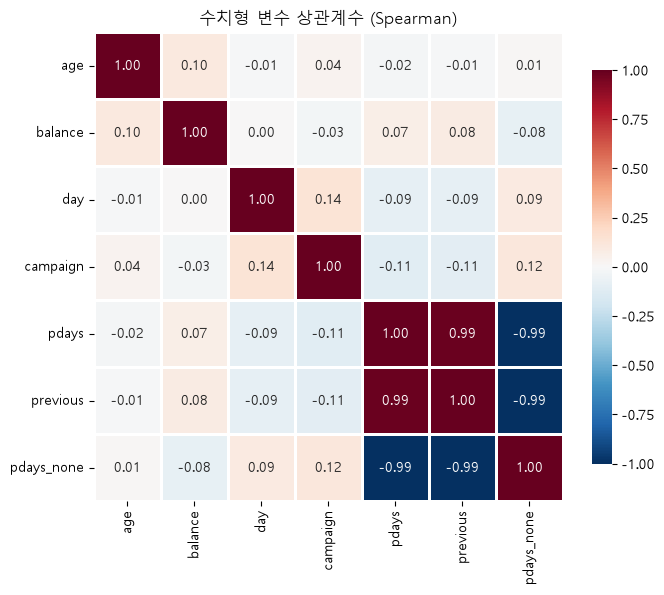

In [24]:
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'pdays_none']
corr = df_clean[num_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor='white', cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('수치형 변수 상관계수 (Spearman)')
plt.tight_layout(); plt.show()

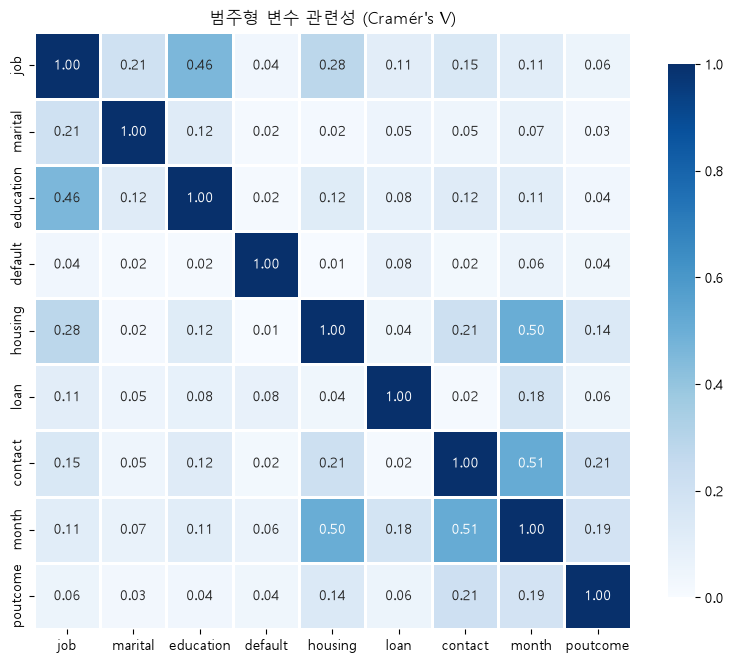

In [25]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
cv = pd.DataFrame([[cramers_v(df_clean[a], df_clean[b]) for b in cat_cols] for a in cat_cols],
                  index=cat_cols, columns=cat_cols)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(cv, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True,
            linewidths=1, linecolor='white', cbar_kws={'shrink': .8}, ax=ax)
ax.set_title("범주형 변수 관련성 (Cramér's V)")
plt.tight_layout(); plt.show()

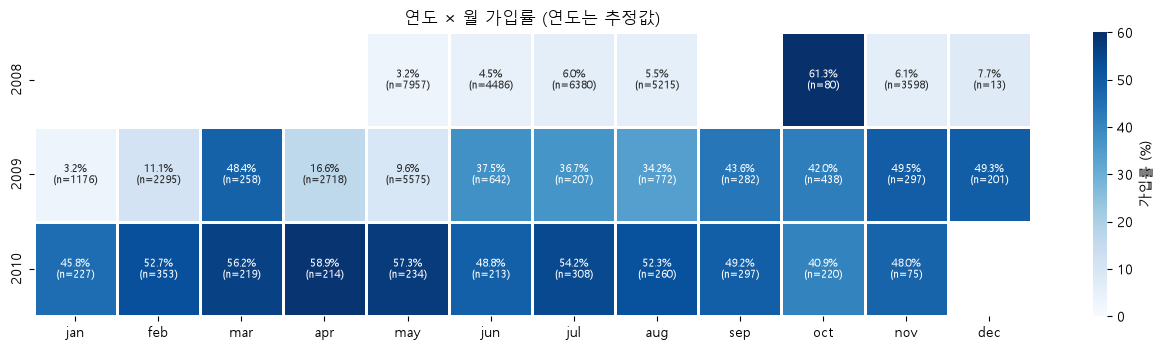

In [26]:
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_num = df_clean['month'].map({m: i + 1 for i, m in enumerate(month_order)})
year_est = 2008 + (month_num.diff() < 0).cumsum()        # 행 순서로 추정한 연도 (시작 2008년)

tmp = df_clean.assign(year_est=year_est, yes=(df_clean['y'] == 'yes'))
rate = tmp.pivot_table(index='year_est', columns='month', values='yes', aggfunc='mean')[month_order] * 100
cnt = tmp.pivot_table(index='year_est', columns='month', values='y', aggfunc='size')[month_order]

label = rate.round(1).astype(str) + '%\n(n=' + cnt.fillna(0).astype(int).astype(str) + ')'
label = label.where(cnt.notna(), '')                     # 데이터 없는 칸은 빈칸

fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(rate, annot=label, fmt='', cmap='Blues', vmin=0, vmax=60,
            linewidths=1, linecolor='white', cbar_kws={'label': '가입률 (%)'},
            annot_kws={'size': 8}, ax=ax)
ax.set_title('연도 × 월 가입률 (연도는 추정값)'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

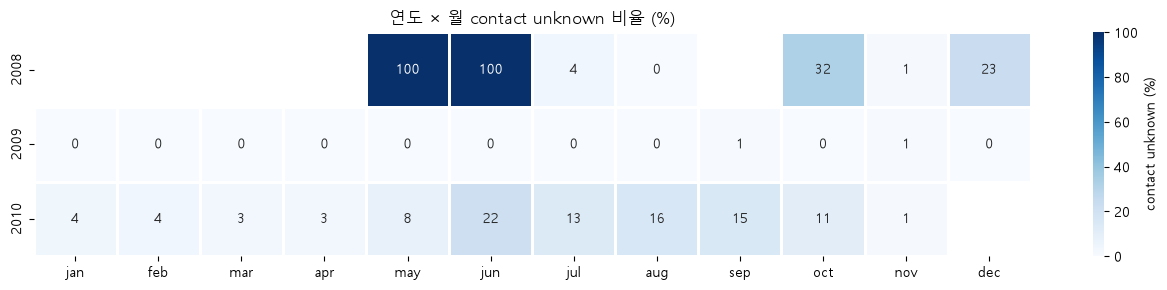

In [27]:
unk = (tmp.assign(u=(tmp['contact'] == 'unknown'))
          .pivot_table(index='year_est', columns='month', values='u', aggfunc='mean')[month_order] * 100)

fig, ax = plt.subplots(figsize=(13, 3))
sns.heatmap(unk, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100,
            linewidths=1, linecolor='white', cbar_kws={'label': 'contact unknown (%)'}, ax=ax)
ax.set_title('연도 × 월 contact unknown 비율 (%)'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

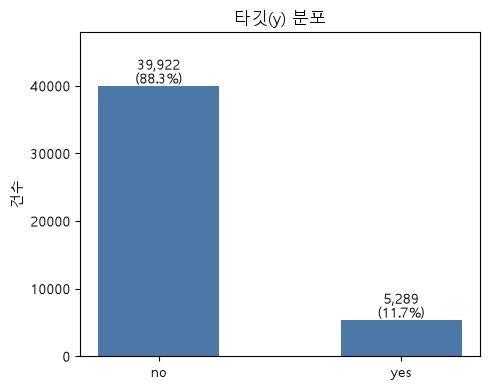

In [28]:
counts = df['y'].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(counts.index, counts.values, color='#4C78A8', width=0.5)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / len(df) * 100:.1f}%)', ha='center', va='bottom')
ax.set_title('타깃(y) 분포'); ax.set_ylabel('건수')
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()

정기예금 가입(yes)은 5,289건(11.7%), 미가입(no)은 39,922건(88.3%)으로 약 1:7.5의 클래스 불균형 존재.  
전부 no로 예측해도 정확도가 88.3%가 되므로, 모델 평가에는 정확도 대신 정밀도·재현율·F1을 사용.

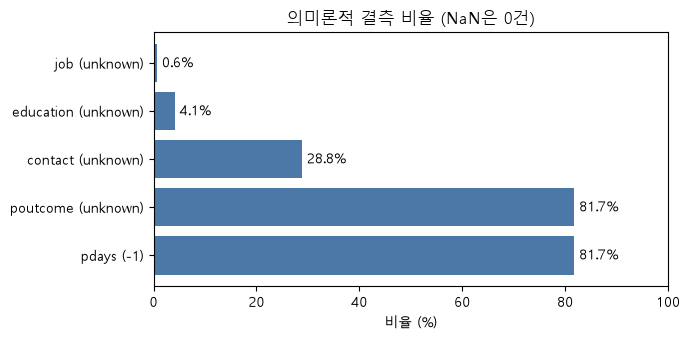

In [29]:
miss = pd.Series({
    'job (unknown)':       (df['job'] == 'unknown').mean(),
    'education (unknown)': (df['education'] == 'unknown').mean(),
    'contact (unknown)':   (df['contact'] == 'unknown').mean(),
    'poutcome (unknown)':  (df['poutcome'] == 'unknown').mean(),
    'pdays (-1)':          (df['pdays'] == -1).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(miss.index, miss.values, color='#4C78A8')
for i, v in enumerate(miss.values):
    ax.text(v + 1, i, f'{v:.1f}%', va='center')
ax.set_xlim(0, 100); ax.set_xlabel('비율 (%)')
ax.set_title('의미론적 결측 비율 (NaN은 0건)')
ax.invert_yaxis()
plt.tight_layout(); plt.show()

표시상 결측(NaN)은 없으나, ‘unknown’과 pdays=-1 형태의 의미론적 결측이 5개 컬럼에 존재.  
poutcome(81.75%)과 pdays(81.74%)의 결측은 이전 캠페인 접촉 이력이 없는(previous=0) 36,954행과 정확히 일치-> 구조적 결측이며,  
job(0.64%)·education(4.11%)·contact(28.80%)는 기록 누락 같음.

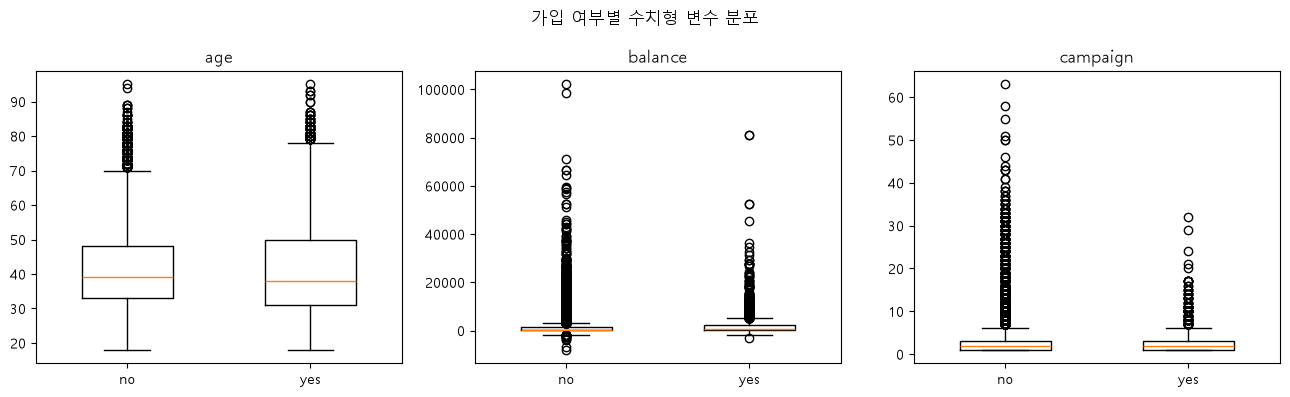

In [30]:
cols = ['age', 'balance', 'campaign']
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, cols):
    data = [df.loc[df['y'] == v, col] for v in ['no', 'yes']]
    ax.boxplot(data, tick_labels=['no', 'yes'], widths=0.5)   # matplotlib 3.9 미만이면 labels=
    ax.set_title(col)
fig.suptitle('가입 여부별 수치형 변수 분포')
plt.tight_layout(); plt.show()

In [31]:
import numpy as np
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency, pointbiserialr

# Train / Test 분할 (중요도는 Train으로만 계산)
X = df_clean.drop(columns=['y', 'duration'])
y = (df_clean['y'] == 'yes').astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()

# ① 통계 방법: 범주형은 Cramér's V, 수치형은 점이연 상관계수 절댓값 (0~1, 클수록 y와 관련 큼)
rows = []
for col in cat_cols:
    t = pd.crosstab(X_train[col], y_train)
    chi2 = chi2_contingency(t)[0]
    rows.append({'변수': col, '종류': '범주형',
                 '관련성': np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))})
for col in num_cols:
    r, _ = pointbiserialr(y_train, X_train[col])
    rows.append({'변수': col, '종류': '수치형', '관련성': abs(r)})
display(pd.DataFrame(rows).set_index('변수').sort_values('관련성', ascending=False).round(3))

,종류,관련성
변수,,
poutcome,범주형,0.311
month,범주형,0.257
pdays_none,수치형,0.164
contact,범주형,0.150
housing,범주형,0.139
job,범주형,0.138
previous,수치형,0.112
pdays,수치형,0.100
campaign,수치형,0.072


In [32]:
df_clean.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,pdays_none
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,0,0,no_prev_campaign,no,1
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,0,0,no_prev_campaign,no,1
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,0,0,no_prev_campaign,no,1
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,0,0,no_prev_campaign,no,1
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,0,0,no_prev_campaign,no,1


pdays_none : 이전 캠페인 연락이 없었는가 없음 1 / 있음 0  넣음  
is_dup	duration을 뺀 기준으로 중복된 행인가 중복 1 / 아님 0 학습시 빼야 함

duration, pdays_none, isdup 컬럼 제거 및 train / test 데이터 분리

In [33]:
import time
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# X, y 분리: duration(통화 후에만 알 수 있어 누수)과 타깃 y 제외
X = df_clean.drop(columns=['y', 'duration', 'is_dup', 'pdays_none'], errors='ignore')
y = (df_clean['y'] == 'yes').astype(int)

# Train / Test 분할 (8:2, stratify로 가입률 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# 확인
print('duration 포함 여부:', 'duration' in X_train.columns)        # False여야 함
print('Train:', X_train.shape, '/ Test:', X_test.shape)

display(pd.DataFrame({
    'Train 건수': y_train.value_counts(),
    'Train 비율': y_train.value_counts(normalize=True).round(3),
    'Test 건수': y_test.value_counts(),
    'Test 비율': y_test.value_counts(normalize=True).round(3),
}).rename(index={0: 'no (0)', 1: 'yes (1)'}))

print('Train 불균형 비율 (no : yes) = 1 :', round((y_train == 0).sum() / (y_train == 1).sum(), 2))

print(X_train.columns.tolist())
print(X_train.shape)

duration 포함 여부: False
Train: (36168, 15) / Test: (9042, 15)


,Train 건수,Train 비율,Test 건수,Test 비율
y,,,,
no (0),31937,0.883,7984,0.883
yes (1),4231,0.117,1058,0.117


Train 불균형 비율 (no : yes) = 1 : 7.55
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
(36168, 15)


> **셀 A. 데이터 정제**
> - pdays -1 → 0 : -1은 일수가 아니라 "이전 연락 없음"이라서
> - poutcome unknown → no_prev_campaign : 이전 캠페인이 없어 결과가 존재하지 않아서 (36,954행)
> - previous = 275 삭제 : 현실적으로 불가능한 입력 오류 (1행)
> - 행마다 규칙으로만 바꿔서 분할 전에 해도 누수 없음

In [34]:
# ═════════════════════════════════════════════
# 셀 A. 데이터 정제 (분할 전: 행마다 규칙으로만 바꾸는 변환)
# ═════════════════════════════════════════════
df_clean = df.copy()                                   # 원본 df는 그대로 보존

# 1) 구조적 결측 처리: 이전 캠페인 접촉이 없는 행 (pdays=-1 ⇔ previous=0)
no_prev = df_clean['previous'] == 0
df_clean.loc[no_prev, 'pdays'] = 0                     # -1(연락 없음) → 0
df_clean.loc[no_prev, 'poutcome'] = 'no_prev_campaign' # 결과가 존재하지 않음 (unknown 5건은 기록 누락으로 유지)

# 2) 입력 오류 삭제: previous=275 (이전 연락일이 데이터 시작 11일 후라 불가능한 값)
df_clean = df_clean[df_clean['previous'] != 275].reset_index(drop=True)

print('df_clean:', df_clean.shape)                                         # (45210, 17)
display(df_clean['poutcome'].value_counts().to_frame('건수'))
print('pdays 최솟값:', df_clean['pdays'].min(), '/ previous 최댓값:', df_clean['previous'].max())

df_clean: (45210, 17)


,건수
poutcome,
no_prev_campaign,36954
failure,4901
other,1839
success,1511
unknown,5


pdays 최솟값: 0 / previous 최댓값: 58


> **셀 B. 데이터 분할**
> - duration 제외 : 통화가 끝나야 알 수 있는 값 (누수)
> - Train 80% / Test 20%, 두 데이터 모두 가입률 11.7%로 유지
> - Test는 최종 평가에만 사용

In [35]:
# ═════════════════════════════════════════════
# 셀 B. X·y 분리 + Train/Test 분할
# ═════════════════════════════════════════════
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42

X = df_clean.drop(columns=['y', 'duration'])           # duration: 통화 후에만 알 수 있어 누수
y = (df_clean['y'] == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '/ Test:', X_test.shape)                  # (36168, 15) / (9042, 15)
print('입력 컬럼:', X_train.columns.tolist())
display(pd.DataFrame({'Train 비율': y_train.value_counts(normalize=True).round(3),
                      'Test 비율': y_test.value_counts(normalize=True).round(3)})
          .rename(index={0: 'no (0)', 1: 'yes (1)'}))

Train: (36168, 15) / Test: (9042, 15)
입력 컬럼: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


,Train 비율,Test 비율
y,,
no (0),0.883,0.883
yes (1),0.117,0.117


> **셀 C. 전처리기 정의 (분할 후)**

| 대상 | 컬럼 | 변환 | 적용 모델 | 이유 |
| --- | --- | --- | --- | --- |
| 범주형 9개 | job, marital, education, default, housing, loan, contact, month, poutcome | 원핫 인코딩 | 둘 다 | 모델은 문자를 계산할 수 없고, 순서가 없는 범주라 숫자 순서를 주면 안 됨 |
| 수치형 6개 | age, balance, day, campaign, pdays, previous | 표준화 (평균 0, 표준편차 1) | 로지스틱 회귀 | 단위가 다른 변수(나이, 잔액 등)를 같은 크기로 맞춰야 계수가 공정하게 계산됨 |
| 수치형 6개 | age, balance, day, campaign, pdays, previous | 표준화 (평균 0, 표준편차 1) | 의사결정나무 | 나무 자체는 영향이 없지만, SMOTE가 거리로 이웃을 찾을 때 범위가 큰 변수가 거리를 독차지하지 않게 하려고 |
| 꼬리가 긴 수치형 2개 | balance (-627 ~ 13,239), campaign (1 ~ 17회) | 1~99% 분위수 캡 | 로지스틱 회귀 | 극단값에 민감한 모델. 값은 실제로 가능해서 삭제하지 않고 범위만 제한 |

- 변환 후 입력 변수: 두 모델 모두 **51개**
- 모든 기준값(범주 목록, 분위수, 평균, 표준편차)은 **Train으로만 계산**하고 Test에는 그대로 적용 → 데이터 누수 방지

In [36]:
# ═════════════════════════════════════════════
# 셀 C. 전처리기 정의 (분할 후: 기준값은 Train으로만 계산)
# ═════════════════════════════════════════════

# 1) 컬럼 구분
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()   # 범주형 9개
num_cols = X_train.select_dtypes(include='number').columns.tolist()   # 수치형 6개
cap_cols = ['balance', 'campaign']                                     # 꼬리가 긴 컬럼
other_num = [c for c in num_cols if c not in cap_cols]

# 2) 캡 변환기: 학습 데이터의 1%·99% 분위수로 값을 자름
class QuantileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower), X.quantile(self.upper)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.lo_, self.hi_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def ohe():
    return OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# ── 셀 C-1 확인 ──
pd.set_option('display.max_colwidth', None)      # 셀 내용이 잘리지 않게

display(pd.DataFrame({'구분': ['범주형', '수치형', '캡 적용'],
                      '컬럼': [', '.join(cat_cols), ', '.join(num_cols), ', '.join(cap_cols)]}))


,구분,컬럼
0,범주형,"job, marital, education, default, housing, loan, contact, month, poutcome"
1,수치형,"age, balance, day, campaign, pdays, previous"
2,캡 적용,"balance, campaign"


In [37]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# 3) 모델별 전처리기
preprocessors = {
    'LogisticRegression': ColumnTransformer([          # 원핫 + 캡 + 표준화
        ('cat', ohe(), cat_cols),
        ('cap', Pipeline([('cap', QuantileCapper()), ('scale', StandardScaler())]), cap_cols),
        ('num', StandardScaler(), other_num)]),
    'DecisionTree': ColumnTransformer([                # 원핫 + 표준화 (SMOTE 거리 계산용)
        ('cat', ohe(), cat_cols),
        ('num', StandardScaler(), num_cols)]),
}

# 4) 확인: 모델별로 Train에 fit → Train·Test 변환 결과 비교
rows = []
for name, prep in preprocessors.items():
    chk = clone(prep).fit(X_train)                     # 확인용 복사본 (원본은 그대로 둠)
    Xtr_t, Xte_t = chk.transform(X_train), chk.transform(X_test)
    i = list(chk.get_feature_names_out()).index('num__age')
    rows.append({'모델': name,
                 '변환 후 컬럼 수': Xtr_t.shape[1],
                 'age 평균 (Train)': Xtr_t[:, i].mean(), 'age 평균 (Test)': Xte_t[:, i].mean(),
                 'age 표준편차 (Train)': Xtr_t[:, i].std(), 'age 표준편차 (Test)': Xte_t[:, i].std()})
display(pd.DataFrame(rows).round(3))

# 캡 경계값 확인 (로지스틱 회귀)
cap = clone(preprocessors['LogisticRegression']).fit(X_train).named_transformers_['cap'].named_steps['cap']
display(pd.DataFrame({'하한(1%)': cap.lo_, '상한(99%)': cap.hi_}))

,모델,변환 후 컬럼 수,age 평균 (Train),age 평균 (Test),age 표준편차 (Train),age 표준편차 (Test)
0,LogisticRegression,51,0.0,0.023,1.0,0.995
1,DecisionTree,51,0.0,0.023,1.0,0.995


,하한(1%),상한(99%)
balance,-627.0,13239.32
campaign,1.0,17.00


평가함수

In [38]:
import time
from sklearn.metrics import (confusion_matrix, average_precision_score, accuracy_score,
                             f1_score, precision_score, recall_score)

def evaluate(model_name, method, pipe, threshold=0.5):
    # 1) Train으로 학습 + 학습시간 측정
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    # 2) Test로 예측: 가입 확률 → 임계값 이상이면 1(가입)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)

    # 3) 지표 계산
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'모델': model_name, '방법': method,
            'PR-AUC': average_precision_score(y_test, proba),
            'Accuracy': accuracy_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            '학습시간(초)': train_time,
            'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn}

In [39]:
from sklearn.pipeline import Pipeline

base_models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(random_state=RANDOM_STATE),
}

results = []
for name, model in base_models.items():
    pipe = Pipeline([('prep', preprocessors[name]), ('model', model)])
    results.append(evaluate(name, 'Baseline', pipe))

display(pd.DataFrame(results).round(3))

results, fitted = [], {}                         # ← fitted 추가
for name, model in base_models.items():
    pipe = Pipeline([('prep', preprocessors[name]), ('model', model)])
    results.append(evaluate(name, 'Baseline', pipe))
    fitted[name] = pipe                          # ← 학습된 모델 저장

display(pd.DataFrame(results).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),TP,FN,FP,TN
0,LogisticRegression,Baseline,0.415,0.892,0.280,0.645,0.179,0.146,189,869,104,7880
1,DecisionTree,Baseline,0.167,0.826,0.293,0.279,0.309,0.306,327,731,844,7140


,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),TP,FN,FP,TN
0,LogisticRegression,Baseline,0.415,0.892,0.280,0.645,0.179,0.223,189,869,104,7880
1,DecisionTree,Baseline,0.167,0.826,0.293,0.279,0.309,0.337,327,731,844,7140


중간 확인

In [40]:
rows = []
for name, pipe in fitted.items():
    for split, X_, y_ in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        proba = pipe.predict_proba(X_)[:, 1]
        rows.append({'모델': name, '데이터': split,
                     'PR-AUC': average_precision_score(y_, proba),
                     'Recall': recall_score(y_, (proba >= 0.5).astype(int))})
display(pd.DataFrame(rows).round(3))

,모델,데이터,PR-AUC,Recall
0,LogisticRegression,Train,0.407,0.177
1,LogisticRegression,Test,0.415,0.179
2,DecisionTree,Train,1.000,1.000
3,DecisionTree,Test,0.167,0.309


LR은 Train/Test 차이가 없어 과적합이 아닌 낮은 재현율 문제,  
DT는 Train PR-AUC 1.000 대 Test 0.167로 과적합이 확인되어 이후 깊이 제한이 필요

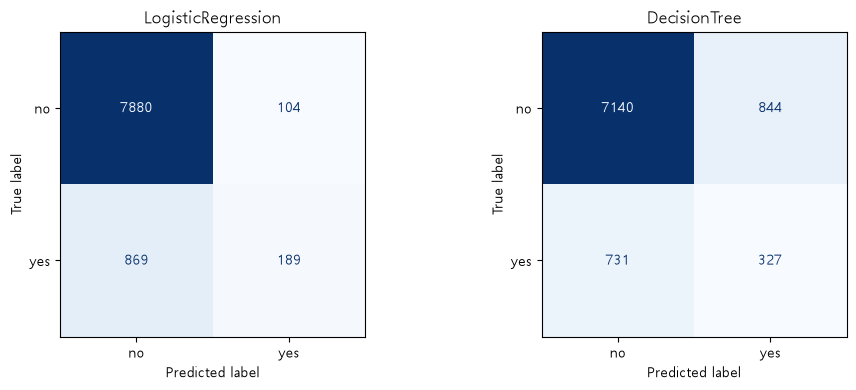

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    pred = pipe.predict(X_test)                    # 기본 임계값 0.5
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['no', 'yes'],
                                            cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

로지스틱 회귀: 너무 조심스러운 모델

Test 9,042명 중 293명(약 3%)만 "가입"이라고 예측했습니다.  
예측하면 10번 중 6번 넘게 맞지만(Precision 0.645), 가입 고객의 82%를 놓칩니다(869 / 1,058).  

의사결정나무: 더 많이 잡지만 헛걸음도 많음

LR보다 138명을 더 잡았지만(327 vs 189), 헛걸음 연락이 8배로 늘었습니다(844 vs 104).  
그래도 가입 고객의 69%를 놓칩니다(731 / 1,058).

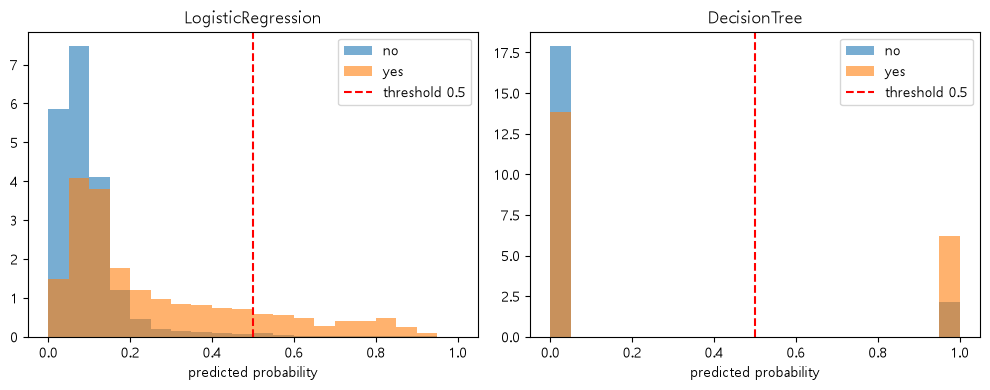

In [42]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bins = np.linspace(0, 1, 21)                        # 0.05 간격 20구간
for ax, (name, pipe) in zip(axes, fitted.items()):
    proba = pipe.predict_proba(X_test)[:, 1]
    ax.hist(proba[y_test.values == 0], bins=bins, alpha=0.6, density=True, label='no')
    ax.hist(proba[y_test.values == 1], bins=bins, alpha=0.6, density=True, label='yes')
    ax.axvline(0.5, color='red', linestyle='--', label='threshold 0.5')
    ax.set_title(name); ax.set_xlabel('predicted probability'); ax.legend()
plt.tight_layout()
plt.show()

교차검증 준비 함수

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'PR-AUC': 'average_precision', 'Accuracy': 'accuracy', 'F1': 'f1',
           'Precision': 'precision', 'Recall': 'recall'}

def cv_evaluate(model_name, method, pipe):
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'모델': model_name, '방법': method}
    row.update({k: s[f'test_{k}'].mean() for k in scoring})   # 5번 평균
    row['학습시간(초)'] = s['fit_time'].mean()
    row['PR-AUC 표준편차'] = s['test_PR-AUC'].std()          # ← 추가된 줄
    return row

클래스 가중치

In [44]:
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()      # no 인원 ÷ yes 인원 (약 7.5)
ratios = {'1:3': 1/3, '1:2': 1/2, '1:1': 1}                 # yes : no 목표 비율

cw_cv = []
for name, model in base_models.items():
    pipe = Pipeline([('prep', clone(preprocessors[name])), ('model', clone(model))])
    cw_cv.append(cv_evaluate(name, 'Baseline', pipe))

    for label, r in ratios.items():
        w = {0: 1, 1: neg_pos * r}
        pipe = Pipeline([('prep', clone(preprocessors[name])),
                         ('model', clone(model).set_params(class_weight=w))])
        cw_cv.append(cv_evaluate(name, f'ClassWeight {label}', pipe))

display(pd.DataFrame(cw_cv).round(3))


,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,Baseline,0.403,0.892,0.277,0.646,0.177,0.189,0.009
1,LogisticRegression,ClassWeight 1:3,0.402,0.886,0.404,0.520,0.331,0.211,0.008
2,LogisticRegression,ClassWeight 1:2,0.401,0.876,0.436,0.465,0.411,0.233,0.008
3,LogisticRegression,ClassWeight 1:1,0.400,0.754,0.373,0.266,0.624,0.236,0.007
4,DecisionTree,Baseline,0.178,0.832,0.315,0.301,0.330,0.313,0.006
5,DecisionTree,ClassWeight 1:3,0.176,0.833,0.309,0.301,0.319,0.296,0.003
6,DecisionTree,ClassWeight 1:2,0.176,0.834,0.309,0.302,0.317,0.248,0.004
7,DecisionTree,ClassWeight 1:1,0.177,0.836,0.311,0.305,0.317,0.232,0.006


언더샘플링

In [45]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

rus_cv = []
for name, model in base_models.items():
    for label, r in ratios.items():
        pipe = ImbPipeline([('prep', clone(preprocessors[name])),
                            ('sampler', RandomUnderSampler(sampling_strategy=r, random_state=RANDOM_STATE)),
                            ('model', clone(model))])
        rus_cv.append(cv_evaluate(name, f'RUS {label}', pipe))

display(pd.DataFrame(rus_cv).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,RUS 1:3,0.401,0.886,0.404,0.518,0.332,0.121,0.008
1,LogisticRegression,RUS 1:2,0.399,0.876,0.439,0.467,0.415,0.115,0.007
2,LogisticRegression,RUS 1:1,0.395,0.752,0.371,0.264,0.624,0.101,0.007
3,DecisionTree,RUS 1:3,0.176,0.766,0.321,0.243,0.473,0.179,0.002
4,DecisionTree,RUS 1:2,0.174,0.726,0.314,0.222,0.537,0.150,0.004
5,DecisionTree,RUS 1:1,0.160,0.634,0.286,0.185,0.626,0.124,0.006


SMOTE

In [46]:
from imblearn.over_sampling import SMOTE

smote_cv = []
for name, model in base_models.items():
    for label, r in ratios.items():
        pipe = ImbPipeline([('prep', clone(preprocessors[name])),
                            ('sampler', SMOTE(sampling_strategy=r, random_state=RANDOM_STATE)),
                            ('model', clone(model))])
        smote_cv.append(cv_evaluate(name, f'SMOTE {label}', pipe))

display(pd.DataFrame(smote_cv).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,SMOTE 1:3,0.401,0.886,0.406,0.523,0.332,0.339,0.010
1,LogisticRegression,SMOTE 1:2,0.400,0.875,0.440,0.463,0.419,0.384,0.010
2,LogisticRegression,SMOTE 1:1,0.398,0.746,0.363,0.257,0.619,0.498,0.010
3,DecisionTree,SMOTE 1:3,0.177,0.826,0.316,0.293,0.343,0.490,0.003
4,DecisionTree,SMOTE 1:2,0.172,0.823,0.304,0.282,0.331,0.426,0.008
5,DecisionTree,SMOTE 1:1,0.170,0.821,0.301,0.277,0.331,0.561,0.009


In [47]:
all_cv = pd.DataFrame(cw_cv + rus_cv + smote_cv)
display(all_cv.sort_values(['모델', 'Recall'], ascending=[True, False]).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
13,DecisionTree,RUS 1:1,0.160,0.634,0.286,0.185,0.626,0.124,0.006
12,DecisionTree,RUS 1:2,0.174,0.726,0.314,0.222,0.537,0.150,0.004
11,DecisionTree,RUS 1:3,0.176,0.766,0.321,0.243,0.473,0.179,0.002
17,DecisionTree,SMOTE 1:3,0.177,0.826,0.316,0.293,0.343,0.490,0.003
18,DecisionTree,SMOTE 1:2,0.172,0.823,0.304,0.282,0.331,0.426,0.008
19,DecisionTree,SMOTE 1:1,0.170,0.821,0.301,0.277,0.331,0.561,0.009
4,DecisionTree,Baseline,0.178,0.832,0.315,0.301,0.330,0.313,0.006
5,DecisionTree,ClassWeight 1:3,0.176,0.833,0.309,0.301,0.319,0.296,0.003
6,DecisionTree,ClassWeight 1:2,0.176,0.834,0.309,0.302,0.317,0.248,0.004
7,DecisionTree,ClassWeight 1:1,0.177,0.836,0.311,0.305,0.317,0.232,0.006


가중치 세분화

In [48]:
weights = [1, 1.5, 2, 2.5, 3, 4, 5, 6, 7.5, 10, 15]     # ← 여기서 가중치를 바꿉니다

cw2_cv = []
for name, model in base_models.items():
    for wt in weights:
        pipe = Pipeline([('prep', clone(preprocessors[name])),
                         ('model', clone(model).set_params(class_weight={0: 1, 1: wt}))])
        row = cv_evaluate(name, f'yes 가중치 {wt}', pipe)
        row['yes:no 비율'] = f'1:{neg_pos / wt:.1f}'
        cw2_cv.append(row)

display(pd.DataFrame(cw2_cv).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차,yes:no 비율
0,LogisticRegression,yes 가중치 1,0.403,0.892,0.277,0.646,0.177,0.161,0.009,1:7.5
1,LogisticRegression,yes 가중치 1.5,0.403,0.890,0.338,0.576,0.240,0.214,0.008,1:5.0
2,LogisticRegression,yes 가중치 2,0.402,0.889,0.378,0.546,0.289,0.207,0.008,1:3.8
3,LogisticRegression,yes 가중치 2.5,0.402,0.886,0.403,0.520,0.329,0.169,0.008,1:3.0
4,LogisticRegression,yes 가중치 3,0.402,0.884,0.422,0.505,0.362,0.207,0.008,1:2.5
5,LogisticRegression,yes 가중치 4,0.401,0.872,0.437,0.451,0.425,0.217,0.008,1:1.9
6,LogisticRegression,yes 가중치 5,0.401,0.852,0.436,0.394,0.489,0.230,0.007,1:1.5
7,LogisticRegression,yes 가중치 6,0.400,0.821,0.415,0.336,0.541,0.243,0.007,1:1.3
8,LogisticRegression,yes 가중치 7.5,0.400,0.757,0.374,0.268,0.619,0.205,0.007,1:1.0
9,LogisticRegression,yes 가중치 10,0.400,0.637,0.323,0.206,0.738,0.214,0.007,1:0.8


In [49]:
no_per_yes = [6, 5, 4, 3, 2.5, 2, 1.5, 1.25, 1]     # ← yes 1명당 남길 no 수 (원래 약 7.5)

rus2_cv = []
for name, model in base_models.items():
    for k in no_per_yes:
        pipe = ImbPipeline([('prep', clone(preprocessors[name])),
                            ('sampler', RandomUnderSampler(sampling_strategy=1/k, random_state=RANDOM_STATE)),
                            ('model', clone(model))])
        rus2_cv.append(cv_evaluate(name, f'RUS 1:{k}', pipe))

display(pd.DataFrame(rus2_cv).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,RUS 1:6,0.402,0.891,0.311,0.602,0.210,0.152,0.008
1,LogisticRegression,RUS 1:5,0.402,0.890,0.339,0.573,0.241,0.194,0.008
2,LogisticRegression,RUS 1:4,0.401,0.890,0.374,0.556,0.282,0.165,0.008
3,LogisticRegression,RUS 1:3,0.401,0.886,0.404,0.518,0.332,0.174,0.008
4,LogisticRegression,RUS 1:2.5,0.400,0.883,0.424,0.502,0.368,0.159,0.008
5,LogisticRegression,RUS 1:2,0.399,0.876,0.439,0.467,0.415,0.149,0.007
6,LogisticRegression,RUS 1:1.5,0.398,0.850,0.434,0.389,0.492,0.146,0.007
7,LogisticRegression,RUS 1:1.25,0.397,0.818,0.413,0.333,0.547,0.137,0.007
8,LogisticRegression,RUS 1:1,0.395,0.752,0.371,0.264,0.624,0.129,0.007
9,DecisionTree,RUS 1:6,0.174,0.817,0.312,0.279,0.354,0.250,0.003


In [50]:
smote2_cv = []
for name, model in base_models.items():
    for k in no_per_yes:                              # F-8과 같은 비율 [6, 5, 4, 3, 2.5, 2, 1.5, 1.25, 1]
        pipe = ImbPipeline([('prep', clone(preprocessors[name])),
                            ('sampler', SMOTE(sampling_strategy=1/k, random_state=RANDOM_STATE)),
                            ('model', clone(model))])
        smote2_cv.append(cv_evaluate(name, f'SMOTE 1:{k}', pipe))

display(pd.DataFrame(smote2_cv).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,SMOTE 1:6,0.403,0.891,0.308,0.597,0.208,0.218,0.010
1,LogisticRegression,SMOTE 1:5,0.402,0.891,0.341,0.577,0.242,0.236,0.010
2,LogisticRegression,SMOTE 1:4,0.402,0.890,0.375,0.559,0.282,0.235,0.010
3,LogisticRegression,SMOTE 1:3,0.401,0.886,0.406,0.523,0.332,0.269,0.010
4,LogisticRegression,SMOTE 1:2.5,0.400,0.883,0.423,0.501,0.366,0.302,0.010
5,LogisticRegression,SMOTE 1:2,0.400,0.875,0.440,0.463,0.419,0.340,0.010
6,LogisticRegression,SMOTE 1:1.5,0.399,0.848,0.430,0.384,0.490,0.354,0.010
7,LogisticRegression,SMOTE 1:1.25,0.398,0.813,0.405,0.322,0.545,0.382,0.010
8,LogisticRegression,SMOTE 1:1,0.398,0.746,0.363,0.257,0.619,0.406,0.010
9,DecisionTree,SMOTE 1:6,0.180,0.829,0.321,0.300,0.346,0.358,0.005


In [51]:
weights = [1, 1.5, 2, 2.5, 3, 4, 5, 6, 7.5, 10, 15]     # ← 여기서 가중치를 바꿉니다

cw3_cv = []
for name, model in base_models.items():
    for wt in weights:
        pipe = Pipeline([('prep', clone(preprocessors[name])),
                         ('model', clone(model).set_params(class_weight={0: 1, 1: wt}))])
        row = cv_evaluate(name, f'yes 가중치 {wt}', pipe)
        row['yes:no 비율'] = f'1:{neg_pos / wt:.1f}'
        cw2_cv.append(row)

display(pd.DataFrame(cw3_cv).round(3))

""


각각 다 딱히 PR 바뀌는 건 없는데 언더샘플링은 데이터 많이 버리는 것 같고 smote는 비슷한데 느려서 그냥 클래스가중치로  
1, 2.5, 4, 7.5

모델링 준비

In [52]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

cw_options = [None, {0: 1, 1: 2.5}, {0: 1, 1: 4}, {0: 1, 1: 7.5}]
tuned = {}

def show_search(name, search, top=5):
    res = pd.DataFrame(search.cv_results_)
    params = [c for c in res.columns if c.startswith('param_')]
    metrics = {f'mean_test_{k}': k for k in scoring}                 # F-1의 scoring 지표 5개
    out = (res.sort_values('rank_test_PR-AUC')
              [params + list(metrics) + ['std_test_PR-AUC', 'mean_fit_time']]
              .rename(columns={**metrics, 'std_test_PR-AUC': 'PR-AUC 표준편차',
                               'mean_fit_time': '학습시간(초)'}))
    display(out.head(top).round(4))
    print(f'{name} 최적 설정:', search.best_params_)
    tuned[name] = search

로지스틱 회귀

In [53]:
lr_pipe = Pipeline([('prep', clone(preprocessors['LogisticRegression'])),
                    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

lr_grid = {'model__C': [0.01, 0.1, 1, 10],
           'model__class_weight': cw_options}

lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv,
                         scoring=scoring,          # ← 지표 5개 모두 계산
                         refit='PR-AUC',           # ← 최적 조합은 PR-AUC로 고름
                         n_jobs=-1)
lr_search.fit(X_train, y_train)
show_search('LogisticRegression', lr_search)

,param_model__C,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,0.1,None,0.4035,0.8921,0.2637,0.6568,0.1652,0.0091,0.5712
8,1.0,None,0.4032,0.8923,0.2768,0.6457,0.1766,0.0087,0.5242
12,10.0,None,0.4031,0.8922,0.2780,0.6431,0.1777,0.0087,0.4141
5,0.1,"{0: 1, 1: 2.5}",0.4022,0.8861,0.4011,0.5220,0.3259,0.0082,0.4664
9,1.0,"{0: 1, 1: 2.5}",0.4020,0.8859,0.4029,0.5198,0.3292,0.0080,0.5435


LogisticRegression 최적 설정: {'model__C': 0.1, 'model__class_weight': None}


C : 계수(컬럼별 점수)를 얼마나 크게 허락할지	0.1~10에서 계수가 거의 같아 성능 차이 없음  
class_weight : yes를 틀렸을 때 벌점을 몇 배로 할지	확률이 전체적으로 올라 Recall은 오르지만 순서(PR-AUC)는 그대로

In [54]:
lr = tuned['LogisticRegression'].best_estimator_
coef = pd.Series(lr.named_steps['model'].coef_[0], index=lr.named_steps['prep'].get_feature_names_out())
display(coef.sort_values(key=abs, ascending=False).head(15).round(3).to_frame('계수'))

,계수
cat__poutcome_success,1.420
cat__month_mar,1.017
cat__contact_unknown,-0.925
cat__month_jan,-0.916
cat__month_nov,-0.760
cat__poutcome_failure,-0.757
cat__month_aug,-0.712
cat__month_sep,0.648
cat__month_oct,0.643
cat__poutcome_no_prev_campaign,-0.607


디시전트리

In [55]:
dt_pipe = Pipeline([('prep', clone(preprocessors['DecisionTree'])),
                    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))])

dt_grid = {'model__max_depth': [4, 6, 8, 10, 12, 15, 20],
           'model__min_samples_leaf': [10, 30, 50, 100, 200],
           'model__class_weight': cw_options}

dt_search = GridSearchCV(dt_pipe, dt_grid, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1)
dt_search.fit(X_train, y_train)
show_search('DecisionTree', dt_search)
tuned['DecisionTree'].best_params_

,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
33,None,20,100,0.4050,0.8921,0.3137,0.6169,0.2111,0.0148,0.4321
28,None,15,100,0.4036,0.8921,0.3137,0.6169,0.2111,0.0148,0.3536
138,"{0: 1, 1: 7.5}",20,100,0.4027,0.7421,0.3686,0.2585,0.6431,0.0111,0.2718
132,"{0: 1, 1: 7.5}",15,50,0.4013,0.7407,0.3750,0.2613,0.6649,0.0090,0.3289
133,"{0: 1, 1: 7.5}",15,100,0.4013,0.7419,0.3684,0.2583,0.6429,0.0106,0.2997


DecisionTree 최적 설정: {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 100}


{'model__class_weight': None,
 'model__max_depth': 20,
 'model__min_samples_leaf': 100}

In [56]:
dt = tuned['DecisionTree'].best_estimator_
imp = pd.Series(dt.named_steps['model'].feature_importances_, index=dt.named_steps['prep'].get_feature_names_out())
display(imp.sort_values(ascending=False).head(15).round(3).to_frame('중요도'))

,중요도
cat__poutcome_success,0.427
num__age,0.105
num__day,0.060
num__pdays,0.057
cat__contact_unknown,0.048
cat__month_jun,0.048
cat__month_mar,0.042
num__balance,0.040
cat__month_oct,0.031
cat__month_apr,0.027


랜덤포레스트

In [57]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([('prep', clone(preprocessors['DecisionTree'])),
                    ('model', RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_STATE))])

rf_grid = {'model__max_depth': [8, 12, 16, None],
           'model__min_samples_leaf': [1, 5, 10, 20],
           'model__max_features': ['sqrt', 0.3, 0.5],
           'model__class_weight': cw_options}

rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=20, cv=cv, scoring=scoring, refit='PR-AUC',
                               n_jobs=-1, random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
show_search('RandomForest', rf_search)

,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
15,10,0.3,16,None,0.4441,0.8942,0.3057,0.6597,0.1990,0.0132,14.0956
10,10,0.3,16,"{0: 1, 1: 2.5}",0.4420,0.8838,0.4503,0.5043,0.4070,0.0122,13.6371
7,10,0.3,12,None,0.4418,0.8945,0.2977,0.6751,0.1912,0.0120,12.2686
13,5,0.3,12,"{0: 1, 1: 2.5}",0.4417,0.8862,0.4435,0.5185,0.3876,0.0123,12.2966
17,5,0.5,12,"{0: 1, 1: 2.5}",0.4410,0.8853,0.4455,0.5130,0.3940,0.0114,17.4455


RandomForest 최적 설정: {'model__min_samples_leaf': 10, 'model__max_features': 0.3, 'model__max_depth': 16, 'model__class_weight': None}


In [58]:
res = pd.DataFrame(rf_search.cv_results_)
res['가중치'] = res['param_model__class_weight'].astype(str)
cols = ['가중치', 'param_model__max_depth', 'param_model__min_samples_leaf', 'param_model__max_features',
        'mean_test_PR-AUC', 'mean_test_F1', 'mean_test_Precision', 'mean_test_Recall']
display(res.sort_values('mean_test_PR-AUC', ascending=False).groupby('가중치').head(1)[cols].round(3))

,가중치,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_PR-AUC,mean_test_F1,mean_test_Precision,mean_test_Recall
10,"{0: 1, 1: 2.5}",16,10,0.3,0.442,0.450,0.504,0.407
4,"{0: 1, 1: 4}",12,5,0.3,0.440,0.473,0.469,0.477
5,"{0: 1, 1: 7.5}",16,5,0.5,0.438,0.460,0.387,0.569


In [59]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

more_models = {
    'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
}
prep_tree = preprocessors['DecisionTree']       # 나무 모델 공통 전처리 (원핫 + 표준화)

In [60]:
cw_cv2 = []
for name, model in more_models.items():
    pipe = Pipeline([('prep', clone(prep_tree)), ('model', clone(model))])
    cw_cv2.append(cv_evaluate(name, 'Baseline', pipe))

    for label, r in ratios.items():
        w = {0: 1, 1: neg_pos * r}
        pipe = Pipeline([('prep', clone(prep_tree)),
                         ('model', clone(model).set_params(class_weight=w))])
        cw_cv2.append(cv_evaluate(name, f'ClassWeight {label}', pipe))

display(pd.DataFrame(cw_cv2).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,RandomForest,Baseline,0.412,0.892,0.334,0.605,0.230,2.560,0.015
1,RandomForest,ClassWeight 1:3,0.407,0.887,0.401,0.529,0.323,2.664,0.011
2,RandomForest,ClassWeight 1:2,0.406,0.884,0.409,0.504,0.345,2.866,0.013
3,RandomForest,ClassWeight 1:1,0.404,0.877,0.427,0.469,0.393,2.219,0.013
4,LightGBM,Baseline,0.444,0.894,0.353,0.621,0.247,0.276,0.012
5,LightGBM,ClassWeight 1:3,0.444,0.882,0.462,0.493,0.436,0.279,0.012
6,LightGBM,ClassWeight 1:2,0.444,0.874,0.483,0.464,0.505,0.314,0.013
7,LightGBM,ClassWeight 1:1,0.441,0.824,0.450,0.355,0.614,0.286,0.014


feature 추가 (통화량)  
시기	하루 통화량	가입률
2008년 5~8월 : 많음 (하루 수백 통) 낮음 (3~6%)  
2009~2010년	: 적음 (하루 수십 통) 높음 (35~58%)  

통화를 많이 거는 날은 넓은 고객층에 일괄로 거는 날이고,  
적게 거는 날은 선별된 고객에게 집중해서 거는 날일 수 있다고 생각. 

In [61]:
# 1) 행 순서로 연도 추정 (행이 날짜순이라는 가정: 월이 크게 줄어들면 다음 해)
months = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_num = df_clean['month'].map({m: i for i, m in enumerate(months, start=1)})
year = 2008 + (month_num.diff().fillna(0) < -6).cumsum()
display(year.value_counts().sort_index().to_frame('행 수'))

# 2) 같은 날짜(연-월-일)의 통화 수
call_date = year.astype(str) + '-' + month_num.astype(str).str.zfill(2) + '-' + df_clean['day'].astype(str).str.zfill(2)
calls_per_day = call_date.map(call_date.value_counts())

# 3) 확인: 통화량 구간별 가입률 (Train만)
chk = pd.DataFrame({'calls_per_day': calls_per_day.loc[X_train.index], 'y': y_train})
chk['통화량 구간'] = pd.qcut(chk['calls_per_day'], 5, duplicates='drop')
display(chk.groupby('통화량 구간', observed=True)['y']
           .agg(['count', 'mean']).rename(columns={'count': '행 수', 'mean': '가입률'}).round(3))

,행 수
month,
2008,27729
2009,14861
2010,2620


,행 수,가입률
통화량 구간,,
"(0.999, 229.0]",7371,0.352
"(229.0, 319.0]",7311,0.075
"(319.0, 398.0]",7175,0.046
"(398.0, 508.0]",7227,0.046
"(508.0, 825.0]",7084,0.061


통화량 피쳐 붙여서 새 데이터 생성및 새 전처리

In [62]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1) 통화량 세는 변환기: fit에서 학습 데이터의 날짜별 통화 수를 셈
class CallsPerDay(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        dates = pd.DataFrame(X).iloc[:, 0]
        self.share_ = dates.value_counts() / len(dates)          # 날짜별 통화 '비율'
        return self
    def transform(self, X):
        dates = pd.DataFrame(X).iloc[:, 0]
        return dates.map(self.share_).fillna(0).to_frame('calls_per_day').values
    def get_feature_names_out(self, input_features=None):
        return np.array(['calls_per_day'], dtype=object)

# 2) 날짜 컬럼만 붙인 새 데이터 (통화 수는 아직 안 셈)
X_train2, X_test2 = X_train.copy(), X_test.copy()
X_train2['call_date'] = call_date.loc[X_train.index]
X_test2['call_date']  = call_date.loc[X_test.index]

# 3) 새 전처리기: 기존 구조 + 통화량(세기 → 표준화)
calls_pipe = Pipeline([('count', CallsPerDay()), ('scale', StandardScaler())])
preprocessors2 = {
    'LogisticRegression': ColumnTransformer([
        ('cat', ohe(), cat_cols),
        ('cap', Pipeline([('cap', QuantileCapper()), ('scale', StandardScaler())]), cap_cols),
        ('num', StandardScaler(), other_num),
        ('calls', calls_pipe, ['call_date'])]),
    'DecisionTree': ColumnTransformer([
        ('cat', ohe(), cat_cols),
        ('num', StandardScaler(), num_cols),
        ('calls', calls_pipe, ['call_date'])]),
}

# 4) 새 데이터용 교차검증 함수
def cv_evaluate2(model_name, method, pipe):
    s = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'모델': model_name, '방법': method}
    row.update({k: s[f'test_{k}'].mean() for k in scoring})
    row['학습시간(초)'] = s['fit_time'].mean()
    row['PR-AUC 표준편차'] = s['test_PR-AUC'].std()
    return row

# 확인
chk = clone(preprocessors2['DecisionTree']).fit(X_train2)
names = list(chk.get_feature_names_out())
print('변환 후 컬럼 수:', len(names), '/ 마지막 컬럼:', names[-1])

변환 후 컬럼 수: 52 / 마지막 컬럼: calls__calls_per_day


In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 기본 모델 (셀 E와 같음)
base_models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(random_state=RANDOM_STATE),
}

# 불균형 비율 (셀 F-2와 같음)
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()
ratios = {'1:3': 1/3, '1:2': 1/2, '1:1': 1}

# 교차검증 설정 (셀 F-1과 같음)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'PR-AUC': 'average_precision', 'Accuracy': 'accuracy', 'F1': 'f1',
           'Precision': 'precision', 'Recall': 'recall'}

print('neg_pos:', round(neg_pos, 2))

neg_pos: 7.55


로지스틱, DT 기본 가중치로 돌려보기

In [64]:
cw_cv_new = []
for name, model in base_models.items():
    pipe = Pipeline([('prep', clone(preprocessors2[name])), ('model', clone(model))])
    cw_cv_new.append(cv_evaluate2(name, 'Baseline', pipe))

    for label, r in ratios.items():
        w = {0: 1, 1: neg_pos * r}
        pipe = Pipeline([('prep', clone(preprocessors2[name])),
                         ('model', clone(model).set_params(class_weight=w))])
        cw_cv_new.append(cv_evaluate2(name, f'ClassWeight {label}', pipe))

display(pd.DataFrame(cw_cv_new).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,Baseline,0.449,0.895,0.317,0.664,0.208,0.251,0.009
1,LogisticRegression,ClassWeight 1:3,0.448,0.879,0.476,0.484,0.469,0.250,0.008
2,LogisticRegression,ClassWeight 1:2,0.447,0.864,0.488,0.436,0.553,0.255,0.008
3,LogisticRegression,ClassWeight 1:1,0.445,0.811,0.446,0.339,0.650,0.239,0.008
4,DecisionTree,Baseline,0.181,0.834,0.321,0.308,0.335,0.280,0.005
5,DecisionTree,ClassWeight 1:3,0.183,0.835,0.324,0.311,0.339,0.288,0.006
6,DecisionTree,ClassWeight 1:2,0.182,0.837,0.321,0.313,0.329,0.295,0.008
7,DecisionTree,ClassWeight 1:1,0.187,0.842,0.330,0.327,0.333,0.256,0.009


RF, LightGBM, XGBoost 기본값 + 가중치

In [65]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

more_models2 = {
    'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss'),
}

more_cv_new = []
for name, model in more_models2.items():
    pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])), ('model', clone(model))])
    more_cv_new.append(cv_evaluate2(name, 'Baseline', pipe))

    for label, r in ratios.items():
        w = neg_pos * r
        m = clone(model)
        if name == 'XGBoost':
            m.set_params(scale_pos_weight=w)          # XGBoost는 이름만 다름
        else:
            m.set_params(class_weight={0: 1, 1: w})
        pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])), ('model', m)])
        more_cv_new.append(cv_evaluate2(name, f'ClassWeight {label}', pipe))

display(pd.DataFrame(more_cv_new).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,RandomForest,Baseline,0.444,0.893,0.364,0.598,0.262,2.158,0.010
1,RandomForest,ClassWeight 1:3,0.441,0.889,0.454,0.536,0.394,2.422,0.003
2,RandomForest,ClassWeight 1:2,0.435,0.884,0.463,0.506,0.427,2.148,0.005
3,RandomForest,ClassWeight 1:1,0.439,0.878,0.485,0.480,0.490,1.967,0.006
4,LightGBM,Baseline,0.471,0.895,0.386,0.618,0.281,0.264,0.005
5,LightGBM,ClassWeight 1:3,0.470,0.882,0.505,0.496,0.515,0.391,0.003
6,LightGBM,ClassWeight 1:2,0.472,0.873,0.511,0.465,0.569,0.272,0.007
7,LightGBM,ClassWeight 1:1,0.474,0.843,0.485,0.394,0.632,0.293,0.008
8,XGBoost,Baseline,0.451,0.893,0.399,0.582,0.303,0.607,0.008
9,XGBoost,ClassWeight 1:3,0.445,0.884,0.475,0.504,0.449,0.617,0.003


5	LightGBM	ClassWeight 1:3	0.470	0.882	0.505	0.496	0.515	0.391	0.003  
6	LightGBM	ClassWeight 1:2	0.472	0.873	0.511	0.465	0.569	0.272	0.007  
-> F1 기본+가중치 정도로 0.5는 넘었는데 5fold로 교차검증해보기

In [72]:
# 교차검증

lgbm_12 = Pipeline([('prep', clone(preprocessors2['DecisionTree'])),
                    ('model', LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
                                             class_weight={0: 1, 1: neg_pos / 2}))])
s = cross_validate(lgbm_12, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=-1)
display(pd.DataFrame({k: s[f'test_{k}'] for k in ['PR-AUC', 'F1', 'Precision', 'Recall']},
                     index=[f'fold {i+1}' for i in range(5)]).round(3))

,PR-AUC,F1,Precision,Recall
fold 1,0.473,0.525,0.482,0.577
fold 2,0.468,0.506,0.450,0.578
fold 3,0.483,0.504,0.462,0.555
fold 4,0.463,0.507,0.464,0.559
fold 5,0.473,0.515,0.465,0.576


In [67]:
import sys
sys.executable

'c:\\first-project\\.venv\\Scripts\\python.exe'

In [69]:
import catboost
catboost.__version__

'1.2.10'

In [93]:
from catboost import CatBoostClassifier

# 1) CatBoost용 전처리: 범주형·수치형은 그대로 두고, call_date만 통화 비율로 바꿈
prep_cb = ColumnTransformer(
    [('keep', 'passthrough', cat_cols + num_cols),
     ('calls', CallsPerDay(), ['call_date'])],
    verbose_feature_names_out=False).set_output(transform='pandas')

# 2) CatBoost 전용 교차검증 함수
def cv_evaluate_cb2(method, model):
    pipe = Pipeline([('prep', clone(prep_cb)), ('model', model)])
    s = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=1,
                       params={'model__cat_features': cat_cols})       # 범주형 컬럼 알려주기
    row = {'모델': 'CatBoost', '방법': method}
    row.update({k: s[f'test_{k}'].mean() for k in scoring})
    row['학습시간(초)'] = s['fit_time'].mean()
    row['PR-AUC 표준편차'] = s['test_PR-AUC'].std()
    return row

# 3) Baseline + Class Weight
cb_cv_new = [cv_evaluate_cb2('Baseline', CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, thread_count=-1))]
for label, r in ratios.items():
    model = CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
                               scale_pos_weight=float(neg_pos * r))
    cb_cv_new.append(cv_evaluate_cb2(f'ClassWeight {label}', model))

display(pd.DataFrame(cb_cv_new).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,CatBoost,Baseline,0.473,0.897,0.398,0.627,0.292,160.018,0.009
1,CatBoost,ClassWeight 1:3,0.475,0.884,0.503,0.506,0.501,137.160,0.007
2,CatBoost,ClassWeight 1:2,0.476,0.874,0.510,0.468,0.561,131.940,0.007
3,CatBoost,ClassWeight 1:1,0.473,0.843,0.487,0.395,0.636,140.163,0.005


catboost 시간 너무 걸려서 LR, LightGBM, XGBoost 모두 1:2에서 F1 @0.5로 가장 높아서 1:2로 학습 + 나무 300개로 조정

In [ ]:
from catboost import CatBoostClassifier

# 1) CatBoost용 전처리: 범주형·수치형은 그대로, call_date만 통화 비율로 바꿈
prep_cb = ColumnTransformer(
    [('keep', 'passthrough', cat_cols + num_cols),
     ('calls', CallsPerDay(), ['call_date'])],
    verbose_feature_names_out=False).set_output(transform='pandas')

# 2) CatBoost 전용 교차검증 함수
def cv_evaluate_cb2(method, model):
    pipe = Pipeline([('prep', clone(prep_cb)), ('model', model)])
    s = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=1,
                       params={'model__cat_features': cat_cols})       # 범주형 컬럼 알려주기
    row = {'모델': 'CatBoost', '방법': method}
    row.update({k: s[f'test_{k}'].mean() for k in scoring})
    row['학습시간(초)'] = s['fit_time'].mean()
    row['PR-AUC 표준편차'] = s['test_PR-AUC'].std()
    return row

# 3) 나무 300개: Baseline + Class Weight 1:2
CB_ITER = 300                                                            # 기본값 1,000 → 300 (시간 절약)

cb_cv_new = []
cb_cv_new.append(cv_evaluate_cb2(f'Baseline (나무 {CB_ITER})',
                 CatBoostClassifier(iterations=CB_ITER, random_seed=RANDOM_STATE, verbose=0, thread_count=-1)))
cb_cv_new.append(cv_evaluate_cb2(f'ClassWeight 1:2 (나무 {CB_ITER})',
                 CatBoostClassifier(iterations=CB_ITER, random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
                                    scale_pos_weight=float(neg_pos / 2))))

display(pd.DataFrame(cb_cv_new).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,CatBoost,Baseline (나무 300),0.469,0.896,0.396,0.623,0.290,36.543,0.010
1,CatBoost,ClassWeight 1:2 (나무 300),0.471,0.874,0.510,0.469,0.559,36.233,0.006


In [75]:
import time
t = time.time()
m = Pipeline([('prep', clone(prep_cb)), ('model', CatBoostClassifier(random_seed=RANDOM_STATE, verbose=200, thread_count=-1))])
m.fit(X_train2, y_train, model__cat_features=cat_cols)
print('1회 학습 시간(초):', round(time.time() - t, 1))

Learning rate set to 0.04768
0:	learn: 0.6470869	total: 99ms	remaining: 1m 38s
200:	learn: 0.2662953	total: 28.4s	remaining: 1m 53s
400:	learn: 0.2569077	total: 57.5s	remaining: 1m 25s
600:	learn: 0.2491983	total: 1m 22s	remaining: 54.8s
800:	learn: 0.2414563	total: 1m 48s	remaining: 26.9s
999:	learn: 0.2350442	total: 2m 12s	remaining: 0us
1회 학습 시간(초): 133.4


In [78]:
lgbm_w = []
for k in [3, 2.5, 2.25, 2, 1.75, 1.5]:                       # yes 1명당 no 수
    w = neg_pos / k
    pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])),
                     ('model', LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
                                              class_weight={0: 1, 1: w}))])
    lgbm_w.append(cv_evaluate2('LightGBM', f'ClassWeight 1:{k}', pipe))
display(pd.DataFrame(lgbm_w).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LightGBM,ClassWeight 1:3,0.470,0.882,0.505,0.496,0.515,0.313,0.003
1,LightGBM,ClassWeight 1:2.5,0.475,0.878,0.512,0.483,0.546,0.304,0.005
2,LightGBM,ClassWeight 1:2.25,0.474,0.876,0.513,0.474,0.559,0.290,0.007
3,LightGBM,ClassWeight 1:2,0.472,0.873,0.511,0.465,0.569,0.290,0.007
4,LightGBM,ClassWeight 1:1.75,0.473,0.869,0.512,0.455,0.585,0.267,0.009
5,LightGBM,ClassWeight 1:1.5,0.474,0.864,0.506,0.440,0.594,0.290,0.007


lgm 하이퍼 파라미터 조정

In [79]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMClassifier

# 탐색 결과를 표로 보여 주는 함수 (G-0과 같음)
cw_options = [None, {0: 1, 1: neg_pos / 3}, {0: 1, 1: neg_pos / 2}, {0: 1, 1: neg_pos}]   # 없음, 1:3, 1:2, 1:1
tuned2 = {}

def show_search(name, search, top=5):
    res = pd.DataFrame(search.cv_results_)
    params = [c for c in res.columns if c.startswith('param_')]
    metrics = {f'mean_test_{k}': k for k in scoring}
    out = (res.sort_values('rank_test_PR-AUC')[params + list(metrics) + ['std_test_PR-AUC', 'mean_fit_time']]
              .rename(columns={**metrics, 'std_test_PR-AUC': 'PR-AUC 표준편차', 'mean_fit_time': '학습시간(초)'}))
    display(out.head(top).round(4))
    print(f'{name} 최적 설정:', search.best_params_)
    tuned2[name] = search

# LightGBM
lgbm_pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])),
                      ('model', LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1))])

lgbm_grid = {'model__n_estimators': [200, 500, 1000],
             'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
             'model__num_leaves': [15, 31, 63],
             'model__min_child_samples': [20, 50, 100],
             'model__colsample_bytree': [0.5, 0.8, 1.0],
             'model__subsample': [0.7, 1.0],
             'model__subsample_freq': [1],
             'model__reg_lambda': [0, 1, 5],
             'model__class_weight': cw_options}

lgbm_search = RandomizedSearchCV(lgbm_pipe, lgbm_grid, n_iter=40, cv=cv, scoring=scoring, refit='PR-AUC',
                                 n_jobs=-1, random_state=RANDOM_STATE)
lgbm_search.fit(X_train2, y_train)
show_search('LightGBM', lgbm_search)


,param_model__subsample_freq,param_model__subsample,param_model__reg_lambda,param_model__num_leaves,param_model__n_estimators,param_model__min_child_samples,param_model__learning_rate,param_model__colsample_bytree,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,1,0.7,0,31,1000,20,0.01,1.0,"{0: 1, 1: 3.7741668636256205}",0.4780,0.8728,0.5140,0.4650,0.5748,0.0061,3.3227
21,1,1.0,0,63,200,100,0.01,0.8,None,0.4780,0.8954,0.2955,0.6989,0.1877,0.0081,1.0983
33,1,1.0,0,63,200,50,0.03,0.5,"{0: 1, 1: 3.7741668636256205}",0.4778,0.8731,0.5137,0.4658,0.5729,0.0049,0.9534
39,1,0.7,1,15,200,100,0.05,0.8,None,0.4777,0.8968,0.3853,0.6355,0.2768,0.0092,0.6303
0,1,0.7,5,63,500,100,0.01,1.0,"{0: 1, 1: 7.548333727251241}",0.4776,0.8389,0.4853,0.3876,0.6490,0.0075,2.7215


LightGBM 최적 설정: {'model__subsample_freq': 1, 'model__subsample': 0.7, 'model__reg_lambda': 0, 'model__num_leaves': 31, 'model__n_estimators': 1000, 'model__min_child_samples': 20, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0, 'model__class_weight': {0: 1, 1: np.float64(3.7741668636256205)}}


그리드

In [82]:
from sklearn.model_selection import GridSearchCV

lgbm_grid2 = {'model__learning_rate': [0.01, 0.02, 0.03],
              'model__n_estimators': [500, 1000, 1500],
              'model__num_leaves': [15, 31, 63],
              'model__min_child_samples': [20, 50],
              'model__colsample_bytree': [1.0],
              'model__subsample': [0.7],
              'model__subsample_freq': [1],
              'model__reg_lambda': [0],
              'model__class_weight': [{0: 1, 1: neg_pos / 2}]}           # 3 × 3 × 3 × 2 = 54개

lgbm_grid_search = GridSearchCV(lgbm_pipe, lgbm_grid2, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1)
lgbm_grid_search.fit(X_train2, y_train)
show_search('LightGBM (grid)', lgbm_grid_search)

,param_model__class_weight,param_model__colsample_bytree,param_model__learning_rate,param_model__min_child_samples,param_model__n_estimators,param_model__num_leaves,param_model__reg_lambda,param_model__subsample,param_model__subsample_freq,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
28,"{0: 1, 1: 3.7741668636256205}",1.0,0.02,50,500,31,0,0.7,1,0.4791,0.8726,0.5150,0.4644,0.5781,0.0073,1.8974
11,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,50,500,63,0,0.7,1,0.4790,0.8720,0.5159,0.4627,0.5831,0.0062,2.9291
2,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,20,500,63,0,0.7,1,0.4787,0.8722,0.5144,0.4633,0.5784,0.0060,2.3736
18,"{0: 1, 1: 3.7741668636256205}",1.0,0.02,20,500,15,0,0.7,1,0.4784,0.8708,0.5139,0.4591,0.5838,0.0073,1.5090
10,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,50,500,31,0,0.7,1,0.4782,0.8705,0.5154,0.4585,0.5888,0.0063,2.0913


LightGBM (grid) 최적 설정: {'model__class_weight': {0: 1, 1: np.float64(3.7741668636256205)}, 'model__colsample_bytree': 1.0, 'model__learning_rate': 0.02, 'model__min_child_samples': 50, 'model__n_estimators': 500, 'model__num_leaves': 31, 'model__reg_lambda': 0, 'model__subsample': 0.7, 'model__subsample_freq': 1}


In [84]:
show_search('LightGBM (grid)', lgbm_grid_search)

,param_model__class_weight,param_model__colsample_bytree,param_model__learning_rate,param_model__min_child_samples,param_model__n_estimators,param_model__num_leaves,param_model__reg_lambda,param_model__subsample,param_model__subsample_freq,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
28,"{0: 1, 1: 3.7741668636256205}",1.0,0.02,50,500,31,0,0.7,1,0.4791,0.8726,0.5150,0.4644,0.5781,0.0073,1.8974
11,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,50,500,63,0,0.7,1,0.4790,0.8720,0.5159,0.4627,0.5831,0.0062,2.9291
2,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,20,500,63,0,0.7,1,0.4787,0.8722,0.5144,0.4633,0.5784,0.0060,2.3736
18,"{0: 1, 1: 3.7741668636256205}",1.0,0.02,20,500,15,0,0.7,1,0.4784,0.8708,0.5139,0.4591,0.5838,0.0073,1.5090
10,"{0: 1, 1: 3.7741668636256205}",1.0,0.01,50,500,31,0,0.7,1,0.4782,0.8705,0.5154,0.4585,0.5888,0.0063,2.0913


LightGBM (grid) 최적 설정: {'model__class_weight': {0: 1, 1: np.float64(3.7741668636256205)}, 'model__colsample_bytree': 1.0, 'model__learning_rate': 0.02, 'model__min_child_samples': 50, 'model__n_estimators': 500, 'model__num_leaves': 31, 'model__reg_lambda': 0, 'model__subsample': 0.7, 'model__subsample_freq': 1}


In [85]:
def best_row(name, search):
    res = pd.DataFrame(search.cv_results_)
    r = res.loc[res['rank_test_PR-AUC'] == 1].iloc[0]
    row = {'탐색': name}
    row.update({k: r[f'mean_test_{k}'] for k in scoring})
    row['PR-AUC 표준편차'] = r['std_test_PR-AUC']
    row['학습시간(초)'] = r['mean_fit_time']
    return row

display(pd.DataFrame([best_row('LightGBM 무작위 (40개)', lgbm_search),
                      best_row('LightGBM 그리드 (54개)', lgbm_grid_search)]).round(4))

,탐색,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
0,LightGBM 무작위 (40개),0.4780,0.8728,0.514,0.4650,0.5748,0.0061,3.3227
1,LightGBM 그리드 (54개),0.4791,0.8726,0.515,0.4644,0.5781,0.0073,1.8974


LGBM 그리드서치 설정 후 최종

In [91]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_validate

# 그리드서치 1위 설정
lgbm_best = Pipeline([
    ('prep', clone(preprocessors2['DecisionTree'])),            # 원본 + 하루 통화량
    ('model', LGBMClassifier(
        n_estimators=500,
        learning_rate=0.02,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.7, subsample_freq=1,
        colsample_bytree=1.0,
        reg_lambda=0,
        class_weight={0: 1, 1: neg_pos / 2},                     # 1:2
        random_state=RANDOM_STATE, n_jobs=1, verbose=-1))])

s = cross_validate(lgbm_best, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=-1)

folds = pd.DataFrame({k: s[f'test_{k}'] for k in scoring}, index=[f'fold {i+1}' for i in range(5)])
folds['학습시간(초)'] = s['fit_time']
folds.loc['평균'] = folds.mean()
folds.loc['표준편차'] = folds.iloc[:5].std()
display(folds.round(3))

,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초)
fold 1,0.476,0.876,0.523,0.475,0.582,1.980
fold 2,0.476,0.869,0.509,0.453,0.580,1.988
fold 3,0.491,0.874,0.516,0.468,0.576,1.951
fold 4,0.469,0.873,0.513,0.466,0.571,1.967
fold 5,0.483,0.871,0.514,0.460,0.582,1.949
평균,0.479,0.873,0.515,0.464,0.578,1.967
표준편차,0.008,0.003,0.005,0.008,0.005,0.017


XGBoost 하이퍼파라미터 조정

In [81]:
from xgboost import XGBClassifier

xgb_pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])),
                     ('model', XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss'))])

xgb_grid = {'model__n_estimators': [200, 500, 1000],
            'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
            'model__max_depth': [3, 4, 5, 6, 8],
            'model__min_child_weight': [1, 5, 10],
            'model__subsample': [0.7, 0.85, 1.0],
            'model__colsample_bytree': [0.5, 0.8, 1.0],
            'model__reg_lambda': [1, 5, 10],
            'model__scale_pos_weight': [1, neg_pos / 3, neg_pos / 2, neg_pos]}   # 없음, 1:3, 1:2, 1:1

xgb_search = RandomizedSearchCV(xgb_pipe, xgb_grid, n_iter=40, cv=cv, scoring=scoring, refit='PR-AUC',
                                n_jobs=-1, random_state=RANDOM_STATE)
xgb_search.fit(X_train2, y_train)
show_search('XGBoost', xgb_search)

,param_model__subsample,param_model__scale_pos_weight,param_model__reg_lambda,param_model__n_estimators,param_model__min_child_weight,param_model__max_depth,param_model__learning_rate,param_model__colsample_bytree,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
0,0.70,2.5161,10,200,10,6,0.03,1.0,0.4810,0.8810,0.5139,0.4924,0.5377,0.0063,2.0931
28,0.85,3.7742,1,1000,10,6,0.01,0.5,0.4793,0.8736,0.5147,0.4673,0.5729,0.0077,5.9412
34,0.70,3.7742,10,200,10,8,0.01,1.0,0.4790,0.8740,0.5166,0.4687,0.5755,0.0034,1.9399
1,1.00,3.7742,10,1000,5,5,0.01,0.5,0.4790,0.8721,0.5153,0.4631,0.5810,0.0103,4.6084
14,0.70,7.5483,5,500,5,5,0.03,0.5,0.4788,0.8427,0.4897,0.3948,0.6450,0.0092,2.8186


XGBoost 최적 설정: {'model__subsample': 0.7, 'model__scale_pos_weight': np.float64(2.51611124241708), 'model__reg_lambda': 10, 'model__n_estimators': 200, 'model__min_child_weight': 10, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}


In [ ]:
xgb_grid2 = {'model__learning_rate': [0.01, 0.02, 0.03],
             'model__n_estimators': [200, 500, 1000],
             'model__max_depth': [5, 6, 8],
             'model__min_child_weight': [5, 10],
             'model__subsample': [0.7],
             'model__colsample_bytree': [1.0],
             'model__reg_lambda': [10],
             'model__scale_pos_weight': [neg_pos / 3]}                  # 3 × 3 × 3 × 2 = 54개

xgb_grid_search = GridSearchCV(xgb_pipe, xgb_grid2, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1)
xgb_grid_search.fit(X_train2, y_train)
show_search('XGBoost (grid)', xgb_grid_search)

,param_model__colsample_bytree,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,param_model__n_estimators,param_model__reg_lambda,param_model__scale_pos_weight,param_model__subsample,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
16,1.0,0.01,8,10,500,10,2.5161,0.7,0.4828,0.8823,0.5099,0.4975,0.5233,0.0055,4.1443
33,1.0,0.02,8,10,200,10,2.5161,0.7,0.4826,0.8820,0.5108,0.4961,0.5266,0.0073,1.7544
10,1.0,0.01,6,10,500,10,2.5161,0.7,0.4818,0.8803,0.5115,0.4899,0.5353,0.0058,3.4884
7,1.0,0.01,6,5,500,10,2.5161,0.7,0.4817,0.8804,0.5124,0.4904,0.5368,0.0054,3.6371
5,1.0,0.01,5,10,1000,10,2.5161,0.7,0.4815,0.8808,0.5114,0.4915,0.5332,0.0057,5.7619


XGBoost (grid) 최적 설정: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.01, 'model__max_depth': 8, 'model__min_child_weight': 10, 'model__n_estimators': 500, 'model__reg_lambda': 10, 'model__scale_pos_weight': np.float64(2.51611124241708), 'model__subsample': 0.7}


XGBoost 그리드 서치 최종

In [94]:
# J-2c: XGBoost 그리드 최적 설정으로 5-fold 결과 표
import time
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier

xgb_best = Pipeline([
    ('prep', clone(preprocessors2['DecisionTree'])),   # 원핫 + 스케일 + 통화량(train에서만 셈)
    ('model', XGBClassifier(
        n_estimators=500,
        learning_rate=0.01,
        max_depth=8,
        min_child_weight=10,
        subsample=0.7,
        colsample_bytree=1.0,
        reg_lambda=10,
        scale_pos_weight=neg_pos / 3,   # = 2.516 (가중치 1:3)
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
res = cross_validate(xgb_best, X_train2, y_train, cv=cv, scoring=scoring,
                     return_train_score=True, n_jobs=1)
total_time = time.time() - start

# fold별 표
fold_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(cv.get_n_splits())],
    'PR-AUC': res['test_PR-AUC'],
    'Precision': res['test_Precision'],
    'Recall': res['test_Recall'],
    'F1': res['test_F1'],
    'Accuracy': res['test_Accuracy'],
    'Train PR-AUC': res['train_PR-AUC'],      # 과적합 확인용
    '학습시간(초)': res['fit_time']
})

# 평균, 표준편차 행 추가
mean_row = fold_df.drop(columns='Fold').mean().to_frame().T
mean_row.insert(0, 'Fold', '평균')
std_row = fold_df.drop(columns='Fold').std().to_frame().T
std_row.insert(0, 'Fold', '표준편차')

result_df = pd.concat([fold_df, mean_row, std_row], ignore_index=True).round(4)
display(result_df)
print(f'전체 소요 시간: {total_time:.1f}초')

,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4839,0.5149,0.5319,0.5233,0.8866,0.5939,1.4890
1,Fold 2,0.4822,0.4748,0.5343,0.5028,0.8764,0.5911,1.0612
2,Fold 3,0.4882,0.5046,0.5218,0.5131,0.8840,0.5928,1.0896
3,Fold 4,0.4719,0.4994,0.5177,0.5084,0.8829,0.5925,0.8557
4,Fold 5,0.4836,0.4917,0.5236,0.5072,0.8810,0.5880,0.9200
5,평균,0.4820,0.4971,0.5259,0.5109,0.8822,0.5917,1.0831
6,표준편차,0.0060,0.0150,0.0070,0.0078,0.0038,0.0023,0.2468


전체 소요 시간: 6.8초


In [89]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_validate

# 그리드서치 1위 설정
lgbm_best = Pipeline([
    ('prep', clone(preprocessors2['DecisionTree'])),            # 원본 + 하루 통화량
('model', XGBClassifier(n_estimators=500, learning_rate=0.01, max_depth=8, min_child_weight=10,
                        subsample=0.7, colsample_bytree=1.0, reg_lambda=10,
                        scale_pos_weight=neg_pos / 3,                     # 1:3
                        random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss'))])

s = cross_validate(lgbm_best, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=-1)

folds = pd.DataFrame({k: s[f'test_{k}'] for k in scoring}, index=[f'fold {i+1}' for i in range(5)])
folds['학습시간(초)'] = s['fit_time']
folds.loc['평균'] = folds.mean()
folds.loc['표준편차'] = folds.iloc[:5].std()
display(folds.round(3))

,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초)
fold 1,0.486,0.886,0.519,0.511,0.527,4.184
fold 2,0.483,0.877,0.503,0.476,0.533,4.336
fold 3,0.488,0.884,0.512,0.505,0.518,4.217
fold 4,0.472,0.883,0.507,0.501,0.513,4.371
fold 5,0.485,0.882,0.509,0.495,0.525,4.191
평균,0.483,0.882,0.510,0.497,0.523,4.260
표준편차,0.006,0.003,0.006,0.013,0.008,0.088


In [86]:
display(pd.DataFrame([best_row('LightGBM 무작위 (40개)', lgbm_search),
                      best_row('LightGBM 그리드 (54개)', lgbm_grid_search),
                      best_row('XGBoost 무작위 (40개)', xgb_search),
                      best_row('XGBoost 그리드 (54개)', xgb_grid_search)]).round(4))

,탐색,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
0,LightGBM 무작위 (40개),0.4780,0.8728,0.5140,0.4650,0.5748,0.0061,3.3227
1,LightGBM 그리드 (54개),0.4791,0.8726,0.5150,0.4644,0.5781,0.0073,1.8974
2,XGBoost 무작위 (40개),0.4810,0.8810,0.5139,0.4924,0.5377,0.0063,2.0931
3,XGBoost 그리드 (54개),0.4828,0.8823,0.5099,0.4975,0.5233,0.0055,4.1443


로지스틱회귀 하이퍼 파라미터 조정

In [90]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

lr_pipe = Pipeline([('prep', clone(preprocessors2['LogisticRegression'])),
                    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

lr_grid = {'model__C': [0.01, 0.1, 1, 10],
           'model__class_weight': cw_options}

lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1)
lr_search.fit(X_train2, y_train)
show_search('LogisticRegression', lr_search)

,param_model__C,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,0.10,None,0.4493,0.8947,0.3079,0.6684,0.2002,0.0085,0.6469
8,1.00,None,0.4491,0.8949,0.3167,0.6637,0.2082,0.0085,0.3936
12,10.00,None,0.4490,0.8950,0.3182,0.6645,0.2094,0.0085,0.3089
0,0.01,None,0.4488,0.8941,0.2713,0.6965,0.1685,0.0085,0.3181
5,0.10,"{0: 1, 1: 2.51611124241708}",0.4480,0.8797,0.4780,0.4858,0.4710,0.0082,0.5960


LogisticRegression 최적 설정: {'model__C': 0.1, 'model__class_weight': None}


DT 조정

In [92]:
from sklearn.tree import DecisionTreeClassifier

dt_pipe = Pipeline([('prep', clone(preprocessors2['DecisionTree'])),
                    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))])

dt_grid = {'model__max_depth': [6, 8, 10, 12, 15, 20],
           'model__min_samples_leaf': [20, 50, 100, 200],
           'model__class_weight': cw_options}            # 6 × 4 × 4 = 96개

dt_search = GridSearchCV(dt_pipe, dt_grid, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1)
dt_search.fit(X_train2, y_train)
show_search('DecisionTree', dt_search)

,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
70,"{0: 1, 1: 3.7741668636256205}",20,100,0.4542,0.8632,0.5054,0.4381,0.5975,0.0099,0.3496
62,"{0: 1, 1: 3.7741668636256205}",12,100,0.4540,0.8636,0.5058,0.4393,0.5963,0.0097,0.3376
66,"{0: 1, 1: 3.7741668636256205}",15,100,0.4539,0.8632,0.5054,0.4381,0.5975,0.0100,0.3729
46,"{0: 1, 1: 2.51611124241708}",20,100,0.4522,0.8737,0.5029,0.4669,0.5457,0.0077,0.3614
42,"{0: 1, 1: 2.51611124241708}",15,100,0.4522,0.8737,0.5029,0.4669,0.5457,0.0077,0.3545


DecisionTree 최적 설정: {'model__class_weight': {0: 1, 1: np.float64(3.7741668636256205)}, 'model__max_depth': 20, 'model__min_samples_leaf': 100}


### 누적 가입률 추가하면 좀 달라지니 ..?  
첫 가입~ 바로 직전 가입까지


In [97]:
# M-1: 누적 가입률 변환기 + LightGBM 최적 설정으로 5-fold 표
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline

class CumRate(BaseEstimator, TransformerMixin):
    """첫 통화일 ~ 전날까지 학습 행의 가입률 (오늘 제외)"""
    def fit(self, X, y=None):
        d = pd.DataFrame({'d': pd.DataFrame(X).iloc[:, 0].values, 'y': np.asarray(y)})
        g = d.groupby('d')['y'].agg(['sum', 'count']).sort_index()   # 학습 행만, 날짜별 합계
        self.dates_ = g.index.values
        self.cum_sum_ = g['sum'].cumsum().values                     # 그날까지 누적 가입 수
        self.cum_cnt_ = g['count'].cumsum().values                   # 그날까지 누적 통화 수
        return self
    def transform(self, X):
        d = pd.DataFrame(X).iloc[:, 0].values
        k = np.searchsorted(self.dates_, d, side='left')             # 오늘보다 앞선 날짜 개수
        out = np.full(len(d), np.nan)                                # 이전 기록이 없으면 NaN
        ok = k > 0
        out[ok] = self.cum_sum_[k[ok] - 1] / self.cum_cnt_[k[ok] - 1]
        return out.reshape(-1, 1)
    def get_feature_names_out(self, input_features=None):
        return np.array(['cum_rate'], dtype=object)

# 기존 트리용 전처리(원핫 + 통화량)에 누적 가입률만 추가
prep_cum = clone(preprocessors2['DecisionTree'])
prep_cum.transformers.append(('cum', CumRate(), ['call_date']))

# 기존 LightGBM 최적 설정 그대로
lgbm_cum = Pipeline([
    ('prep', prep_cum),
    ('model', clone(lgbm_best.steps[-1][1]))
])

# 확인: 마지막 컬럼이 cum__cum_rate 인지
check = clone(prep_cum).fit(X_train2, y_train)
print('변환 후 컬럼 수:', len(check.get_feature_names_out()), '/ 마지막 컬럼:', check.get_feature_names_out()[-1])

fold_table('LightGBM + 누적 가입률', lgbm_cum)

변환 후 컬럼 수: 53 / 마지막 컬럼: cum__cum_rate


KeyboardInterrupt: 

In [96]:
# M-0: fold별 결과 표 함수
import pandas as pd
from sklearn.model_selection import cross_validate

def fold_table(name, pipe):
    res = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=1)
    fold_df = pd.DataFrame({
        'Fold': [f'Fold {i+1}' for i in range(cv.get_n_splits())],
        'PR-AUC': res['test_PR-AUC'],
        'Precision': res['test_Precision'],
        'Recall': res['test_Recall'],
        'F1': res['test_F1'],
        'Accuracy': res['test_Accuracy'],
        'Train PR-AUC': res['train_PR-AUC'],
        '학습시간(초)': res['fit_time']
    })
    mean_row = fold_df.drop(columns='Fold').mean().to_frame().T; mean_row.insert(0, 'Fold', '평균')
    std_row = fold_df.drop(columns='Fold').std().to_frame().T;   std_row.insert(0, 'Fold', '표준편차')
    print(f'===== {name} =====')
    display(pd.concat([fold_df, mean_row, std_row], ignore_index=True).round(4))

fold_table('LightGBM + 누적 가입률', lgbm_cum)

===== LightGBM + 누적 가입률 =====


,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4784,0.4786,0.5957,0.5308,0.8768,0.6174,2.5991
1,Fold 2,0.4764,0.4460,0.5804,0.5044,0.8666,0.6128,2.7460
2,Fold 3,0.4962,0.4631,0.5785,0.5144,0.8721,0.6108,2.7280
3,Fold 4,0.4771,0.4693,0.5792,0.5185,0.8742,0.6134,2.6874
4,Fold 5,0.4953,0.4601,0.5863,0.5156,0.8711,0.6097,2.6609
5,평균,0.4847,0.4634,0.5840,0.5167,0.8722,0.6128,2.6843
6,표준편차,0.0101,0.0121,0.0072,0.0095,0.0038,0.0030,0.0582


그리드서치 돌려서 값 확인

In [101]:
# M-2: 누적 가입률 포함 LightGBM — 현재 최적값 주변만 그리드서치
from sklearn.model_selection import GridSearchCV

cur = lgbm_cum.named_steps['model'].get_params()      # 현재(J-1c) 설정
print('현재 설정:', {k: cur[k] for k in ['learning_rate', 'num_leaves', 'min_child_samples', 'class_weight']})

param_grid = {
    'model__learning_rate':     sorted({cur['learning_rate'] / 2, cur['learning_rate'], cur['learning_rate'] * 2}),
    'model__num_leaves':        sorted({max(7, cur['num_leaves'] // 2), cur['num_leaves'], cur['num_leaves'] * 2}),
    'model__min_child_samples': sorted({max(5, cur['min_child_samples'] // 2), cur['min_child_samples'], cur['min_child_samples'] * 2}),
}

grid_cum = GridSearchCV(lgbm_cum, param_grid, cv=cv, scoring=scoring,
                        refit='PR-AUC', n_jobs=-1, return_train_score=True)
grid_cum.fit(X_train2, y_train)

print('최적 설정:', grid_cum.best_params_)
show_search('LightGBM + 누적 가입률 (grid)', grid_cum, top=5)

현재 설정: {'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 50, 'class_weight': {0: 1, 1: np.float64(3.7741668636256205)}}


c:\first-project\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


최적 설정: {'model__learning_rate': 0.01, 'model__min_child_samples': 25, 'model__num_leaves': 62}


,param_model__learning_rate,param_model__min_child_samples,param_model__num_leaves,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
2,0.01,25,62,0.4869,0.8724,0.5174,0.4642,0.5845,0.0076,2.9944
5,0.01,50,62,0.4867,0.8714,0.5179,0.4614,0.5904,0.0087,3.1058
4,0.01,50,31,0.4858,0.8700,0.5187,0.4576,0.5989,0.0084,2.2143
1,0.01,25,31,0.4856,0.8702,0.5174,0.4579,0.5949,0.0083,2.3633
8,0.01,100,62,0.4854,0.8715,0.5182,0.4617,0.5906,0.0080,2.9964


LightGBM + 누적 가입률 (grid) 최적 설정: {'model__learning_rate': 0.01, 'model__min_child_samples': 25, 'model__num_leaves': 62}


파생변수 통화량 + 누적 가입률 그리드 서치 최종

In [100]:
# M-3: 그리드 최적 설정으로 5-fold 표
from sklearn.base import clone

lgbm_cum2 = clone(grid_cum.best_estimator_)     # 그리드 최적 설정 그대로
print(lgbm_cum2.named_steps['model'].get_params()[['learning_rate','num_leaves','min_child_samples'][0]],
      lgbm_cum2.named_steps['model'].get_params()['num_leaves'],
      lgbm_cum2.named_steps['model'].get_params()['min_child_samples'])

fold_table('LightGBM + 누적 가입률 (grid 최적)', lgbm_cum2)

0.01 62 25
===== LightGBM + 누적 가입률 (grid 최적) =====


,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4862,0.4787,0.5981,0.5318,0.8768,0.6283,3.5753
1,Fold 2,0.4778,0.4488,0.5851,0.5080,0.8674,0.6257,3.7357
2,Fold 3,0.4924,0.4614,0.5714,0.5105,0.8717,0.6220,3.7169
3,Fold 4,0.4800,0.4706,0.5768,0.5183,0.8746,0.6279,3.5058
4,Fold 5,0.4981,0.4617,0.5910,0.5184,0.8716,0.6227,3.9691
5,평균,0.4869,0.4642,0.5845,0.5174,0.8724,0.6253,3.7006
6,표준편차,0.0085,0.0112,0.0107,0.0093,0.0035,0.0029,0.1784


통화량 그리드 서치 완료 + 누적 추가 + 누적 추가 그리드서치 완료

In [104]:
# M-4: 단계별 비교표 (그리드 최종 → + 누적 가입률 → + 재튜닝)
import pandas as pd
from sklearn.model_selection import cross_validate

models = {
    '① 그리드 최종 (원본 + 통화량)':      lgbm_best,
    '② ① + 누적 가입률 (설정 그대로)':    lgbm_cum,
    '③ ② + 그리드 재탐색 (최종)':         lgbm_cum2,
}
metrics = ['PR-AUC', 'Precision', 'Recall', 'F1', 'Accuracy']

summary, fold_pr = [], {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=1)
    row = {'모델': name}
    for m in metrics:
        row[m] = res[f'test_{m}'].mean()
    row['PR-AUC 표준편차'] = res['test_PR-AUC'].std(ddof=1)
    row['과적합 (Train−검증)'] = res['train_PR-AUC'].mean() - res['test_PR-AUC'].mean()
    row['학습시간(초)'] = res['fit_time'].mean()
    summary.append(row)
    fold_pr[name] = res['test_PR-AUC']

# 표 1: 평균 비교
summary_df = pd.DataFrame(summary).set_index('모델')
base = summary_df.iloc[0]
summary_df.loc['변화 (③ − ①)'] = summary_df.iloc[2] - base
display(summary_df.round(4))

# 표 2: fold별 PR-AUC
fold_df = pd.DataFrame(fold_pr, index=[f'Fold {i+1}' for i in range(cv.get_n_splits())])
names = list(models)
fold_df['변화 (③ − ①)'] = fold_df[names[2]] - fold_df[names[0]]
display(fold_df.round(4))
print('통화량보다 오른 fold 수:', int((fold_df['변화 (③ − ①)'] > 0).sum()), '/ 5')

,PR-AUC,Precision,Recall,F1,Accuracy,PR-AUC 표준편차,과적합 (Train−검증),학습시간(초)
모델,,,,,,,,
① 그리드 최종 (원본 + 통화량),0.4791,0.4644,0.5781,0.5150,0.8726,0.0082,0.1292,2.6425
② ① + 누적 가입률 (설정 그대로),0.4847,0.4634,0.5840,0.5167,0.8722,0.0101,0.1281,2.4825
③ ② + 그리드 재탐색 (최종),0.4869,0.4642,0.5845,0.5174,0.8724,0.0085,0.1384,3.4878
변화 (③ − ①),0.0078,-0.0001,0.0064,0.0024,-0.0002,0.0003,0.0093,0.8453


,① 그리드 최종 (원본 + 통화량),② ① + 누적 가입률 (설정 그대로),③ ② + 그리드 재탐색 (최종),변화 (③ − ①)
Fold 1,0.4758,0.4784,0.4862,0.0104
Fold 2,0.4763,0.4764,0.4778,0.0015
Fold 3,0.4910,0.4962,0.4924,0.0015
Fold 4,0.4695,0.4771,0.4800,0.0105
Fold 5,0.4828,0.4953,0.4981,0.0153


통화량보다 오른 fold 수: 5 / 5


In [105]:
# M-5: 누적 가입률 추가 전/후 비교 (랜덤포레스트, 의사결정나무, 로지스틱회귀)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def add_cum(prep, scale=False):
    """기존 전처리에 누적 가입률 추가. 첫날 NaN은 학습 fold 평균으로 채움"""
    steps = [('cum', CumRate()), ('imp', SimpleImputer(strategy='mean'))]
    if scale:
        steps.append(('scale', StandardScaler()))      # 로지스틱회귀용
    p = clone(prep)
    p.transformers.append(('cum', Pipeline(steps), ['call_date']))
    return p

cw = {0: 1, 1: neg_pos / 3}                            # 가중치 1:3
compare_models = {
    # ▼ 각 모델의 최적 설정으로 바꿔주세요
    '의사결정나무': (DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight=cw, random_state=42), 'DecisionTree', False),
    '랜덤포레스트': (RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight=cw, n_jobs=-1, random_state=42), 'DecisionTree', False),
    '로지스틱회귀': (LogisticRegression(C=1, class_weight=cw, max_iter=2000), 'LogisticRegression', True),
}

rows = []
for name, (model, key, scale) in compare_models.items():
    for label, prep in [('기존', clone(preprocessors2[key])), ('+ 누적 가입률', add_cum(preprocessors2[key], scale))]:
        pipe = Pipeline([('prep', prep), ('model', clone(model))])
        res = cross_validate(pipe, X_train2, y_train, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({'모델': name, '특성': label,
                     **{m: res[f'test_{m}'].mean() for m in ['PR-AUC', 'Precision', 'Recall', 'F1']},
                     'PR-AUC 표준편차': res['test_PR-AUC'].std(ddof=1)})
display(pd.DataFrame(rows).set_index(['모델', '특성']).round(4))

PR-AUC  Precision  Recall      F1  PR-AUC 표준편차
모델     특성                                                      
의사결정나무 기존        0.4411     0.4682  0.5464  0.5039       0.0062
       + 누적 가입률  0.4467     0.4654  0.5434  0.5009       0.0046
랜덤포레스트 기존        0.4740     0.4810  0.5334  0.5057       0.0098
       + 누적 가입률  0.4823     0.4783  0.5493  0.5112       0.0076
로지스틱회귀 기존        0.4479     0.4844  0.4692  0.4763       0.0090
       + 누적 가입률  0.4551     0.4789  0.4774  0.4779       0.0130

light lgbm 임계값

In [106]:
# T-1: Train 5-fold 예측으로 F1 최적 임계값 정하기
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

final_model = clone(lgbm_cum2)       # 최종 모델: LightGBM + 누적 가입률 (그리드 최적)

# 각 행을 "그 행이 검증 fold일 때" 예측한 확률 (Train 안에서만)
oof = cross_val_predict(final_model, X_train2, y_train, cv=cv, method='predict_proba')[:, 1]

p, r, t = precision_recall_curve(y_train, oof)
f1 = 2 * p * r / np.clip(p + r, 1e-9, None)
best_thr = t[np.nanargmax(f1[:-1])]

thr_df = pd.DataFrame([
    {'임계값': th,
     'Precision': precision_score(y_train, oof >= th),
     'Recall': recall_score(y_train, oof >= th),
     'F1': f1_score(y_train, oof >= th)}
    for th in [0.5, best_thr]
], index=['기본 (0.5)', 'F1 최적']).round(4)
display(thr_df)
print(f'선택한 임계값: {best_thr:.3f}')

,임계값,Precision,Recall,F1
기본 (0.5),0.5000,0.4641,0.5845,0.5174
F1 최적,0.4975,0.4640,0.5871,0.5183


선택한 임계값: 0.497


,임계값,PR-AUC,Precision,Recall,F1,Accuracy
임계값 기준,,,,,,
기본 (0.5),0.500,0.5097,0.4729,0.6106,0.5330,0.8748
F1 최적 (Train에서 정함),0.497,0.5097,0.4719,0.6106,0.5323,0.8745


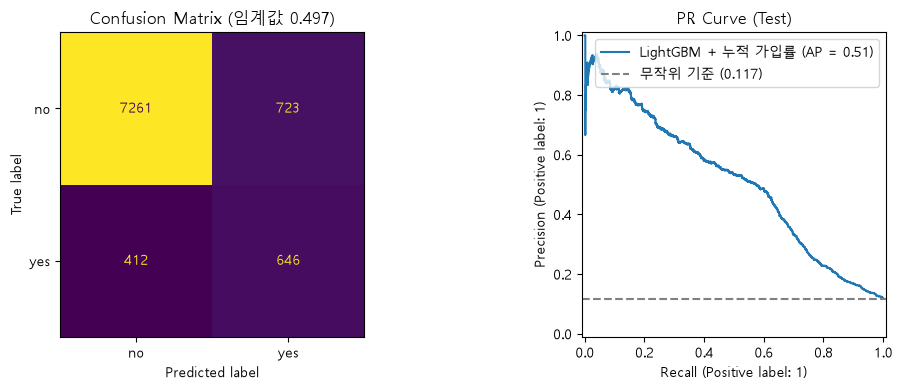

In [107]:
# T-2: Train 전체로 학습 → Test 평가 (한 번만)
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, accuracy_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

final_model.fit(X_train2, y_train)                     # Train 전체로 학습 (누적 가입률도 Train 정답만 사용)
test_proba = final_model.predict_proba(X_test2)[:, 1]

rows = []
for name, th in [('기본 (0.5)', 0.5), ('F1 최적 (Train에서 정함)', best_thr)]:
    pred = (test_proba >= th).astype(int)
    rows.append({'임계값 기준': name, '임계값': round(th, 3),
                 'PR-AUC': average_precision_score(y_test, test_proba),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'Accuracy': accuracy_score(y_test, pred)})
test_df = pd.DataFrame(rows).set_index('임계값 기준').round(4)
display(test_df)

# 혼동행렬 (F1 최적 임계값) + PR 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (test_proba >= best_thr).astype(int),
                                        display_labels=['no', 'yes'], ax=ax[0], colorbar=False)
ax[0].set_title(f'Confusion Matrix (임계값 {best_thr:.3f})')
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=ax[1], name='LightGBM + 누적 가입률')
ax[1].axhline(y_test.mean(), ls='--', c='gray', label=f'무작위 기준 ({y_test.mean():.3f})')
ax[1].legend(); ax[1].set_title('PR Curve (Test)')
plt.tight_layout(); plt.show()

In [108]:
# 최종 모델의 클래스 가중치 확인
cw = final_model.named_steps['model'].get_params()['class_weight']
print('class_weight:', cw)
if isinstance(cw, dict):
    print(f'yes 가중치 {cw[1]:.3f} → 실제 비율(no:yes 약 {neg_pos:.2f}:1)의 1/{neg_pos / cw[1]:.1f} 수준')

class_weight: {0: 1, 1: np.float64(3.7741668636256205)}
yes 가중치 3.774 → 실제 비율(no:yes 약 7.55:1)의 1/2.0 수준
